# IS453 Group Assignment — G1-7 — Medical Procedure Loan
## Credit scorecard: full pipeline in one notebook

From the two raw course files to the final scorecard, cutoff and pricing, using the methods from the Week 9–11 labs.
The write-up `IS453_Group_7_Combined_Notebook_Writeup.md` explains every step and every change from the first version
(`credit_scorecard_medical.py`).

| Part | What it does | Brief component |
|---|---|---|
| 1 | Segment filtering, checkpoint numbers | 2. Data selection |
| 2 | Bureau data cleaning, flattening and left join | 2. Data preparation |
| 3 | Modelling table, correlated variables, train/test split | 2. Data preparation |
| 4 | Fine classing, IV screening, coarse classing | 3. Screening and grouping |
| 5 | Logistic regression, scorecard, AUC/Gini/KS, PCC measures | 4. Logistic regression and performance |
| 6 | Model tuning comparison | 5. Model tuning |
| 7 | Cutoff, expected defaults, profit, break-even interest rate | 6. Cutoff, interest rate, profitability |
| 8 | Three example applicants scored point by point | 7. Scorecard walkthrough |

**Files needed** (in the same folder as this notebook, the same way as `hmeq_data.csv` in the labs):
* `IS453 Group Assignment - Application Data.csv`
* `IS453 Group Assignment - Bureau Data.csv`

**Files this notebook saves** (in the same folder): `g7_iv_fine_classing.csv` (IV of every variable)
`g7_scorecard_points.csv` (the final scorecard) and
`g7_final_bins_and_points.csv` (the final model's bins with counts, bad rates, WOE and points).

The whole notebook takes a few minutes to run. Binning about 40 variables with `sc.woebin` is the slowest step.

## 0. Setup
Same packages as the Week 11 lab. After the two `pip install` lines finish, restart the kernel
and run the cell again, as the lab says. If you see an error about numpy "dtype size changed",
change the first line to `!pip install pandas==2.1.1 "numpy<2"` and restart the kernel again.

In [1]:
!pip install pandas==2.1.1
!pip install scorecardpy==0.1.9.7
# after the installs finish: restart the kernel, then run this cell again

import warnings
warnings.filterwarnings('ignore', category=FutureWarning, module='scorecardpy')

import pandas as pd, numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model, metrics
import scorecardpy as sc
import pprint

print('pandas', pd.__version__, '| scorecardpy', sc.__version__)

/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


pandas 2.1.1 | scorecardpy 0.1.9.7


## Part 1. Segment filtering

**Segment definition** (the group repo's `credit_scorecard_medical.py`):

| # | Filter | Reason |
|---|---|---|
| 1 | `NAME_CONTRACT_TYPE == 'Cash loans'` | a procedure is a one-off cost repaid in fixed instalments, not a revolving credit line |
| 2 | `50,000 <= AMT_CREDIT <= 500,000` | the typical cost range of a medical procedure in the data's currency: leaves out very small purchases and large property or car-sized loans |
| 3 | `25 <= age <= 65` (`-DAYS_BIRTH / 365.25`) | independent adults with elective or restorative medical needs; the upper limit keeps the loan from running into advanced age |
| 4 | `NAME_INCOME_TYPE` in Working, Commercial associate, State servant, Pensioner | a regular income to repay from (excludes students and the unemployed) |
| 5 | `AMT_ANNUITY` not missing and `AMT_INCOME_TOTAL > 0` | the instalment and income must be known to judge affordability |

`ORGANIZATION_TYPE == 'Medicine'` is **not** used: it describes where the applicant works, not why they borrow.
TARGET is only used to count bads. It played no part in choosing the filters.

In [2]:
app = pd.read_csv('IS453 Group Assignment - Application Data.csv', low_memory=False)
assert app['SK_ID_CURR'].is_unique, 'each row should be one application'
app['AGE_YEARS'] = -app['DAYS_BIRTH'] / 365.25

In [3]:
f1 = app['NAME_CONTRACT_TYPE'] == 'Cash loans'
f2 = app['AMT_CREDIT'].between(50000, 500000)
f3 = app['AGE_YEARS'].between(25, 65)
f4 = app['NAME_INCOME_TYPE'].isin(['Working', 'Commercial associate', 'State servant', 'Pensioner'])
f5 = app['AMT_ANNUITY'].notna() & (app['AMT_INCOME_TOTAL'] > 0)

steps = [('Original data', pd.Series(True, index=app.index)),
         ('1. Cash loans', f1),
         ('2. + loan amount 50k-500k', f1 & f2),
         ('3. + age 25-65', f1 & f2 & f3),
         ('4. + income type', f1 & f2 & f3 & f4),
         ('5. + annuity known, income > 0', f1 & f2 & f3 & f4 & f5)]

funnel = pd.DataFrame([dict(step=name, rows=int(m.sum()), bads=int(app.loc[m, 'TARGET'].sum()),
                            bad_rate=app.loc[m, 'TARGET'].mean()) for name, m in steps]).set_index('step')
funnel['share_of_original'] = funnel['rows'] / len(app)
funnel.style.format({'rows': '{:,}', 'bads': '{:,}', 'bad_rate': '{:.2%}', 'share_of_original': '{:.1%}'})

,rows,bads,bad_rate,share_of_original
step,,,,
Original data,"307,511","24,825",8.07%,100.0%
1. Cash loans,"278,232","23,221",8.35%,90.5%
2. + loan amount 50k-500k,"123,413","11,063",8.96%,40.1%
3. + age 25-65,"110,596","10,058",9.09%,36.0%
4. + income type,"110,589","10,055",9.09%,36.0%
"5. + annuity known, income > 0","110,583","10,055",9.09%,36.0%


In [4]:
seg = app[f1 & f2 & f3 & f4 & f5].copy()
base_rate, seg_rate = app['TARGET'].mean(), seg['TARGET'].mean()
print(f"Segment: {len(seg):,} rows, {int(seg['TARGET'].sum()):,} bads, bad rate {seg_rate:.2%}")
print(f"Original: {len(app):,} rows, bad rate {base_rate:.2%}  ->  segment is {seg_rate/base_rate:.2f}x the original bad rate")

Segment: 110,583 rows, 10,055 bads, bad rate 9.09%
Original: 307,511 rows, bad rate 8.07%  ->  segment is 1.13x the original bad rate


In [5]:
# NEW — segment sensitivity: show how each BUSINESS filter changes the population.
# Interpret bad-rate differences descriptively; do not select rules using TARGET after seeing these outcomes.
segment_scenarios = {
    'All applications': pd.Series(True, index=app.index),
    'Cash loans only (baseline)': f1,
    'Cash + 50k-500k': f1 & f2,
    'Cash + amount + income + completeness (no age cap)': f1 & f2 & f4 & f5,
    'Current five filters': f1 & f2 & f3 & f4 & f5,
}
segment_audit = pd.DataFrame([
    {'segment': name, 'rows': int(mask.sum()),
     'bads': int(app.loc[mask, 'TARGET'].sum()),
     'bad_rate': app.loc[mask, 'TARGET'].mean(),
     'retained_pct': mask.mean()}
    for name, mask in segment_scenarios.items()
]).set_index('segment')
assert segment_audit.loc['Current five filters', 'rows'] == len(seg)
print(segment_audit.round(4).to_string())
segment_audit.to_csv('g7_segment_sensitivity.csv')

                                                      rows   bads  bad_rate  retained_pct
segment                                                                                  
All applications                                    307511  24825    0.0807        1.0000
Cash loans only (baseline)                          278232  23221    0.0835        0.9048
Cash + 50k-500k                                     123413  11063    0.0896        0.4013
Cash + amount + income + completeness (no age cap)  123398  11060    0.0896        0.4013
Current five filters                                110583  10055    0.0909        0.3596


**Why the bad rate is higher than the original.** Almost all of the change comes from the loan-amount filter. Among cash
loans, the largest loans (above 500k) are the safest, and mid-sized loans of 250k–500k are the riskiest. The segment keeps
the mid-sized loans and removes the large ones. The age filter also keeps 25–29 year-olds, the riskiest age group.

In [6]:
cash = app[f1]
credit_band = pd.cut(cash['AMT_CREDIT'], [0, 50000, 250000, 500000, 750000, 1000000, np.inf])
cash.groupby(credit_band, observed=True)['TARGET'].agg(rows='size', bad_rate='mean').style.format({'rows': '{:,}', 'bad_rate': '{:.2%}'})

,rows,bad_rate
AMT_CREDIT,,
"(0.0, 50000.0]",561,4.10%
"(50000.0, 250000.0]","44,460",7.25%
"(250000.0, 500000.0]","78,953",9.93%
"(500000.0, 750000.0]","62,891",9.70%
"(750000.0, 1000000.0]","42,089",7.38%
"(1000000.0, inf]","49,278",5.94%


In [7]:
age_band = pd.cut(seg['AGE_YEARS'], [25, 30, 35, 45, 55, 65.01], right=False)
seg.groupby(age_band, observed=True)['TARGET'].agg(rows='size', bad_rate='mean').style.format({'rows': '{:,}', 'bad_rate': '{:.2%}'})

,rows,bad_rate
AGE_YEARS,,
"[25.0, 30.0)","16,514",12.28%
"[30.0, 35.0)","17,008",11.54%
"[35.0, 45.0)","30,371",9.74%
"[45.0, 55.0)","23,861",7.69%
"[55.0, 65.01)","22,829",5.56%


**Does it look like a procedure-loan segment?** Compared with all cash loans, the segment has smaller loans and shorter
terms, which fits one-off procedure costs rather than cars or property.

In [8]:
compare = pd.DataFrame({
    'All cash loans': [cash['AMT_CREDIT'].median(),
                       (cash['AMT_CREDIT'] / cash['AMT_ANNUITY']).median(),
                       cash['AMT_INCOME_TOTAL'].median()],
    'Selected segment': [seg['AMT_CREDIT'].median(),
                         (seg['AMT_CREDIT'] / seg['AMT_ANNUITY']).median(),
                         seg['AMT_INCOME_TOTAL'].median()]},
    index=['Median loan amount (dataset units)',
           'Median credit/annuity ratio (NOT contractual months)',
           'Median annual income (dataset units)'])
print(compare.round(1).to_string())

                                                      All cash loans  Selected segment
Median loan amount (dataset units)                          540000.0          284400.0
Median credit/annuity ratio (NOT contractual months)            20.7              15.5
Median annual income (dataset units)                        153000.0          135000.0


## Part 2. Bureau data: why it cannot be joined directly
The application data has **one row per applicant**. The bureau data has **one row per credit the applicant holds at
other lenders**. A direct left join (Option 1 in the data-merging module) would repeat each applicant once per credit and
create false extra "bad" rows. Spreading credits into columns (Option 2) would give many mostly empty columns. So we use
**Option 3**: summarise each applicant's credits into a set of features, then join one row per applicant.

In [9]:
bureau = pd.read_csv('IS453 Group Assignment - Bureau Data.csv', low_memory=False)
per_applicant = bureau.groupby('SK_ID_CURR').size()
print(f'bureau rows: {len(bureau):,} | applicants: {bureau["SK_ID_CURR"].nunique():,} | '
      f'credits per applicant: median {per_applicant.median():.0f}, max {per_applicant.max()}')

bureau rows: 1,716,428 | applicants: 305,811 | credits per applicant: median 4, max 116


### 2.1 Data quality checks
Run before summarising, because a bad value becomes invisible once it is added into a total.

In [10]:
print('-- issues to fix --')
print(f'negative AMT_CREDIT_SUM_DEBT  : {(bureau.AMT_CREDIT_SUM_DEBT < 0).sum():,}  (a debt cannot be negative)')
print(f'negative AMT_CREDIT_SUM_LIMIT : {(bureau.AMT_CREDIT_SUM_LIMIT < 0).sum():,}  (a limit cannot be negative)')
print(f'DAYS_CREDIT_UPDATE > 0        : {(bureau.DAYS_CREDIT_UPDATE > 0).sum():,}  (updated after the application = future information)')
print(f'DAYS_CREDIT > 0               : {(bureau.DAYS_CREDIT > 0).sum():,}')
print()
print('-- not an issue --')
print(f'DAYS_CREDIT_ENDDATE > 0       : {(bureau.DAYS_CREDIT_ENDDATE > 0).sum():,}  (the credit is still running)')
print()
print(bureau['CREDIT_CURRENCY'].value_counts().to_string())

-- issues to fix --
negative AMT_CREDIT_SUM_DEBT  : 8,418  (a debt cannot be negative)
negative AMT_CREDIT_SUM_LIMIT : 351  (a limit cannot be negative)
DAYS_CREDIT_UPDATE > 0        : 17  (updated after the application = future information)
DAYS_CREDIT > 0               : 0

-- not an issue --
DAYS_CREDIT_ENDDATE > 0       : 602,603  (the credit is still running)

CREDIT_CURRENCY
currency 1    1715020
currency 2       1224
currency 3        174
currency 4         10


### 2.2 Clean
* Drop the credits updated **after** the application date. The bank would not have had that information when deciding (leakage).
* Set negative debts and limits to 0.
* 99.9% of credits are in currency 1 and no exchange rates are given, so other currencies are **flagged**, not converted.
  Their amounts are still added in. Their effect is negligible.

In [11]:
b = bureau[bureau['DAYS_CREDIT_UPDATE'] <= 0].copy()
b['AMT_CREDIT_SUM_DEBT']  = b['AMT_CREDIT_SUM_DEBT'].clip(lower=0)
b['AMT_CREDIT_SUM_LIMIT'] = b['AMT_CREDIT_SUM_LIMIT'].clip(lower=0)
b['IS_FOREIGN_CCY'] = (b['CREDIT_CURRENCY'] != 'currency 1').astype(int)
print(f'{len(bureau):,} -> {len(b):,} rows ({len(bureau) - len(b)} dropped as post-application updates)')

1,716,428 -> 1,716,411 rows (17 dropped as post-application updates)


### 2.3 Yes/no flags for each credit
Each flag is 1 or 0 for each credit, so adding them up per applicant gives a count.
`DAYS_CREDIT` is negative (days before the application), so "opened in the last 12 months" means `DAYS_CREDIT >= -365`.

In [12]:
b['F_ACTIVE']       = (b['CREDIT_ACTIVE'] == 'Active').astype(int)
b['F_CLOSED']       = (b['CREDIT_ACTIVE'] == 'Closed').astype(int)
b['F_BAD_DEBT']     = b['CREDIT_ACTIVE'].isin(['Bad debt', 'Sold']).astype(int)
b['F_OVERDUE_NOW']  = (b['CREDIT_DAY_OVERDUE'] > 0).astype(int)
b['F_EVER_OVERDUE'] = ((b['CREDIT_DAY_OVERDUE'] > 0) | (b['AMT_CREDIT_MAX_OVERDUE'].fillna(0) > 0)).astype(int)
b['F_PROLONGED']    = (b['CNT_CREDIT_PROLONG'] > 0).astype(int)
b['F_CONSUMER']     = (b['CREDIT_TYPE'] == 'Consumer credit').astype(int)
b['F_CARD']         = (b['CREDIT_TYPE'] == 'Credit card').astype(int)
b['F_MICROLOAN']    = (b['CREDIT_TYPE'] == 'Microloan').astype(int)
b['F_SECURED']      = b['CREDIT_TYPE'].isin(['Car loan', 'Mortgage', 'Real estate loan']).astype(int)
b['F_OPENED_12M']   = (b['DAYS_CREDIT'] >= -365).astype(int)
b['F_OPENED_24M']   = (b['DAYS_CREDIT'] >= -730).astype(int)
# amounts on active credits only, so paid-off credits do not count as current debt
b['ACT_DEBT']   = b['AMT_CREDIT_SUM_DEBT'].where(b['F_ACTIVE'] == 1)
b['ACT_CREDIT'] = b['AMT_CREDIT_SUM'].where(b['F_ACTIVE'] == 1)

### 2.4 Summarise to one row per applicant
Only the segment's applicants are summarised. `groupby('SK_ID_CURR').agg(...)` works like a pivot table: one row per
applicant, with each new column built as `NEW_NAME = ('column', 'how')`.

| Family | Features |
|---|---|
| Account counts | total, active, closed, sold / bad debt |
| Delinquency | overdue now, ever overdue, prolonged, worst days and amount overdue |
| Exposure | total credit and debt, active credit and debt, largest and average credit |
| Credit mix | consumer, card, microloan, secured, number of credit types, foreign currency |
| History and recency | first and latest credit, opened in the last 12 and 24 months |

In [13]:
b_seg = b[b['SK_ID_CURR'].isin(seg['SK_ID_CURR'])]

agg = b_seg.groupby('SK_ID_CURR').agg(
    BUR_N_CREDITS        = ('SK_ID_BUREAU', 'count'),
    BUR_N_ACTIVE         = ('F_ACTIVE', 'sum'),
    BUR_N_CLOSED         = ('F_CLOSED', 'sum'),
    BUR_N_BAD_DEBT       = ('F_BAD_DEBT', 'sum'),
    BUR_N_OVERDUE_NOW    = ('F_OVERDUE_NOW', 'sum'),
    BUR_N_EVER_OVERDUE   = ('F_EVER_OVERDUE', 'sum'),
    BUR_N_PROLONGED      = ('F_PROLONGED', 'sum'),
    BUR_MAX_DAYS_OVERDUE = ('CREDIT_DAY_OVERDUE', 'max'),
    BUR_MAX_AMT_OVERDUE  = ('AMT_CREDIT_MAX_OVERDUE', 'max'),
    BUR_SUM_OVERDUE_NOW  = ('AMT_CREDIT_SUM_OVERDUE', 'sum'),
    BUR_SUM_CREDIT       = ('AMT_CREDIT_SUM', 'sum'),
    BUR_SUM_DEBT         = ('AMT_CREDIT_SUM_DEBT', 'sum'),
    BUR_MAX_CREDIT       = ('AMT_CREDIT_SUM', 'max'),
    BUR_MEAN_CREDIT      = ('AMT_CREDIT_SUM', 'mean'),
    BUR_SUM_ACT_DEBT     = ('ACT_DEBT', 'sum'),
    BUR_SUM_ACT_CREDIT   = ('ACT_CREDIT', 'sum'),
    BUR_N_CONSUMER       = ('F_CONSUMER', 'sum'),
    BUR_N_CARD           = ('F_CARD', 'sum'),
    BUR_N_MICROLOAN      = ('F_MICROLOAN', 'sum'),
    BUR_N_SECURED        = ('F_SECURED', 'sum'),
    BUR_N_CREDIT_TYPES   = ('CREDIT_TYPE', 'nunique'),
    BUR_N_FOREIGN_CCY    = ('IS_FOREIGN_CCY', 'sum'),
    BUR_DAYS_FIRST       = ('DAYS_CREDIT', 'min'),
    BUR_DAYS_LAST        = ('DAYS_CREDIT', 'max'),
    BUR_N_OPENED_12M     = ('F_OPENED_12M', 'sum'),
    BUR_N_OPENED_24M     = ('F_OPENED_24M', 'sum'),
).reset_index()

# ratios: a 0 denominator gives a blank (NaN), never 0, so the binning gives it a Missing bin
agg['BUR_UTILISATION']       = agg['BUR_SUM_ACT_DEBT'] / agg['BUR_SUM_ACT_CREDIT'].replace(0, np.nan)
agg['BUR_DEBT_TO_CREDIT']    = agg['BUR_SUM_DEBT'] / agg['BUR_SUM_CREDIT'].replace(0, np.nan)
agg['BUR_SHARE_ACTIVE']      = agg['BUR_N_ACTIVE'] / agg['BUR_N_CREDITS']
agg['BUR_SHARE_OVERDUE']     = agg['BUR_N_EVER_OVERDUE'] / agg['BUR_N_CREDITS']
agg['BUR_HISTORY_YEARS']     = -agg['BUR_DAYS_FIRST'] / 365.25
agg['BUR_MONTHS_SINCE_LAST'] = -agg['BUR_DAYS_LAST'] / 30.44
agg['BUR_EVER_OVERDUE_FLAG'] = (agg['BUR_N_EVER_OVERDUE'] > 0).astype(int)

assert agg['SK_ID_CURR'].is_unique, 'must be one row per applicant'
print(f'{len(b_seg):,} bureau rows for the segment -> {len(agg):,} applicants x {agg.shape[1] - 1} features')
agg.head()

515,493 bureau rows for the segment -> 93,761 applicants x 33 features


,SK_ID_CURR,BUR_N_CREDITS,BUR_N_ACTIVE,BUR_N_CLOSED,BUR_N_BAD_DEBT,BUR_N_OVERDUE_NOW,BUR_N_EVER_OVERDUE,BUR_N_PROLONGED,BUR_MAX_DAYS_OVERDUE,BUR_MAX_AMT_OVERDUE,...,BUR_DAYS_LAST,BUR_N_OPENED_12M,BUR_N_OPENED_24M,BUR_UTILISATION,BUR_DEBT_TO_CREDIT,BUR_SHARE_ACTIVE,BUR_SHARE_OVERDUE,BUR_HISTORY_YEARS,BUR_MONTHS_SINCE_LAST,BUR_EVER_OVERDUE_FLAG
0,100002,8,2,6,0,0,3,0,0,5043.645,...,-103,1,3,0.509931,0.284122,0.250000,0.375,3.934292,3.383706,1
1,100008,3,1,2,0,0,0,0,0,0.000,...,-78,1,1,0.897054,0.512454,0.333333,0.000,3.003422,2.562418,0
2,100015,4,0,4,0,0,0,0,0,NaN,...,-319,1,1,NaN,0.000000,0.000000,0.000,3.857632,10.479632,0
3,100016,7,4,3,0,0,0,0,0,0.000,...,-128,4,5,0.189230,0.134161,0.571429,0.000,4.473648,4.204993,0
4,100026,3,2,1,0,0,0,0,0,0.000,...,-148,2,2,0.858720,0.618278,0.666667,0.000,4.501027,4.862024,0


### 2.5 Left join and missing values
A **left join** keeps every applicant in the segment, including the ones with no bureau record. An inner join would
drop them, and they are a riskier group.

For applicants with no bureau record:

| Feature type | Filled with | Why |
|---|---|---|
| Counts (`BUR_N_...`) and totals (`BUR_SUM_...`), the ever-overdue flag | **0** | no credits means zero accounts and zero debt |
| Ratios, averages, maximums, dates | **left blank** | e.g. a utilisation of 0 would claim they borrow and never use it. A blank gets its own Missing bin later |

In [14]:
zero_fill = [c for c in agg.columns if c.startswith(('BUR_N_', 'BUR_SUM_'))] + ['BUR_EVER_OVERDUE_FLAG']
keep_blank = [c for c in agg.columns if c not in zero_fill + ['SK_ID_CURR']]

model_df = seg.merge(agg, on='SK_ID_CURR', how='left', validate='one_to_one')
model_df['HAS_BUREAU'] = model_df['BUR_N_CREDITS'].notna().astype(int)
model_df[zero_fill] = model_df[zero_fill].fillna(0)

# checks: same applicants, nobody duplicated, bads unchanged
assert len(model_df) == len(seg), 'row count changed during the merge'
assert model_df['SK_ID_CURR'].is_unique, 'an applicant appears twice'
assert model_df['TARGET'].sum() == seg['TARGET'].sum(), 'number of bads changed'
print(f'merged: {model_df.shape[0]:,} rows x {model_df.shape[1]} columns - all checks passed')
print(f'filled with 0 ({len(zero_fill)}): {", ".join(zero_fill)}')
print(f'left blank ({len(keep_blank)}): {", ".join(keep_blank)}')

merged: 110,583 rows x 155 columns - all checks passed
filled with 0 (21): BUR_N_CREDITS, BUR_N_ACTIVE, BUR_N_CLOSED, BUR_N_BAD_DEBT, BUR_N_OVERDUE_NOW, BUR_N_EVER_OVERDUE, BUR_N_PROLONGED, BUR_SUM_OVERDUE_NOW, BUR_SUM_CREDIT, BUR_SUM_DEBT, BUR_SUM_ACT_DEBT, BUR_SUM_ACT_CREDIT, BUR_N_CONSUMER, BUR_N_CARD, BUR_N_MICROLOAN, BUR_N_SECURED, BUR_N_CREDIT_TYPES, BUR_N_FOREIGN_CCY, BUR_N_OPENED_12M, BUR_N_OPENED_24M, BUR_EVER_OVERDUE_FLAG
left blank (12): BUR_MAX_DAYS_OVERDUE, BUR_MAX_AMT_OVERDUE, BUR_MAX_CREDIT, BUR_MEAN_CREDIT, BUR_DAYS_FIRST, BUR_DAYS_LAST, BUR_UTILISATION, BUR_DEBT_TO_CREDIT, BUR_SHARE_ACTIVE, BUR_SHARE_OVERDUE, BUR_HISTORY_YEARS, BUR_MONTHS_SINCE_LAST


In [15]:
# NEW — merge validation and data-quality audit
assert len(model_df) == len(seg)
assert model_df['SK_ID_CURR'].is_unique
assert model_df['TARGET'].isin([0, 1]).all()
assert int(model_df['TARGET'].sum()) == int(seg['TARGET'].sum())
assert (model_df['HAS_BUREAU'] == 0).sum() + (model_df['HAS_BUREAU'] == 1).sum() == len(seg)
assert model_df.loc[model_df['HAS_BUREAU'] == 0, 'BUR_N_CREDITS'].eq(0).all()
print('MERGE AUDIT: all applicant-grain, label, and missing-history checks passed')
print('Foreign-currency bureau credits (check exposure comparability):',
      int((b_seg['CREDIT_CURRENCY'] != 'currency 1').sum()))


MERGE AUDIT: all applicant-grain, label, and missing-history checks passed
Foreign-currency bureau credits (check exposure comparability): 290


### 2.6 Applicants with no bureau record (thin files)

In [16]:
thin = model_df.groupby('HAS_BUREAU')['TARGET'].agg(rows='size', bads='sum', bad_rate='mean')
thin['share'] = thin['rows'] / len(model_df)
thin.index = thin.index.map({0: 'No bureau record', 1: 'Has bureau record'})
thin.style.format({'rows': '{:,}', 'bads': '{:,}', 'bad_rate': '{:.2%}', 'share': '{:.1%}'})

,rows,bads,bad_rate,share
HAS_BUREAU,,,,
No bureau record,"16,822","1,902",11.31%,15.2%
Has bureau record,"93,761","8,153",8.70%,84.8%


### 2.7 Checkpoint summary

In [17]:
print('=' * 70)
print('G1-7 Medical procedure loan - segment and merge summary')
print('=' * 70)
print('filters: cash loans, loan amount 50k-500k, age 25-65, income type, annuity known and income > 0')
print(f'segment: {len(seg):,} rows ({len(seg)/len(app):.1%} of the original {len(app):,})')
print(f'bad rate: {seg_rate:.2%} vs {base_rate:.2%} in the original data')
print(f'bureau: {len(bureau):,} credit rows -> {len(agg):,} applicants with a record, {agg.shape[1]-1} features each')
print(f'merge: left join on SK_ID_CURR, {model_df.shape[0]:,} rows x {model_df.shape[1]} columns, one row per applicant')
print(f"thin files: {(model_df.HAS_BUREAU == 0).sum():,} ({(model_df.HAS_BUREAU == 0).mean():.1%}), "
      f"bad rate {model_df.loc[model_df.HAS_BUREAU == 0, 'TARGET'].mean():.2%} "
      f"vs {model_df.loc[model_df.HAS_BUREAU == 1, 'TARGET'].mean():.2%} with a record")

G1-7 Medical procedure loan - segment and merge summary
filters: cash loans, loan amount 50k-500k, age 25-65, income type, annuity known and income > 0
segment: 110,583 rows (36.0% of the original 307,511)
bad rate: 9.09% vs 8.07% in the original data
bureau: 1,716,428 credit rows -> 93,761 applicants with a record, 33 features each
merge: left join on SK_ID_CURR, 110,583 rows x 155 columns, one row per applicant
thin files: 16,822 (15.2%), bad rate 11.31% vs 8.70% with a record


## Part 3. Modelling table and train/test split
### 3.1 Build the modelling table
Start from the merged table built in Part 2 (application and bureau columns, one row per applicant).
Then, as in the Week 9 lab DIY Q2, **create ratio variables** that combine two fields into something more meaningful:

| New variable | Meaning |
|---|---|
| `CREDIT_TO_INCOME`, `ANNUITY_TO_INCOME` | loan size and monthly instalment relative to income (affordability) |
| `CREDIT_TO_GOODS` | loan amount relative to the procedure price (amount financed on top of the price) |
| `TERM_MONTHS` | loan term, `AMT_CREDIT / AMT_ANNUITY` |
| `DEBT_TO_INCOME` | (existing active bureau debt + this loan) / income |
| `BUR_ANY_MICROLOAN`, `BUR_ANY_OVERDUE_NOW`, `BUR_ANY_BAD_DEBT` | yes/no versions of rare but severe bureau events |
| `ORGANIZATION_TYPE` | sub-types such as "Business Entity Type 1/2/3" grouped into their sector (58 values → 35) |

Day counts are turned into years so the bins are readable. `DAYS_EMPLOYED = 365243` is a placeholder used for pensioners
and the unemployed, so it is set to missing and flagged.

In [18]:
# UPDATED — build one applicant-level modelling table, then split before supervised screening.
flat_cols = ['SK_ID_CURR', 'TARGET'] + [c for c in agg.columns if c != 'SK_ID_CURR'] + ['HAS_BUREAU']
app_cols = [c for c in app.columns if c not in ('SK_ID_CURR', 'TARGET', 'AGE_YEARS')]
df = model_df[flat_cols + app_cols].copy()
assert len(df) == len(seg) and df['SK_ID_CURR'].is_unique

df['AGE_YEARS']          = -df['DAYS_BIRTH'] / 365.25
df['EMP_ANOMALY']        = (df['DAYS_EMPLOYED'] == 365243).astype(int)
df['YEARS_EMPLOYED']     = -df['DAYS_EMPLOYED'].where(df['DAYS_EMPLOYED'] != 365243) / 365.25
df['YEARS_REGISTRATION'] = -df['DAYS_REGISTRATION'] / 365.25
df['YEARS_ID_PUBLISH']   = -df['DAYS_ID_PUBLISH'] / 365.25
df['YEARS_PHONE_CHANGE'] = -df['DAYS_LAST_PHONE_CHANGE'] / 365.25
df = df.drop(columns=['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION',
                      'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE'])

df['CREDIT_TO_INCOME']  = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
df['ANNUITY_TO_INCOME'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
df['CREDIT_TO_GOODS']   = df['AMT_CREDIT'] / df['AMT_GOODS_PRICE']
# Keep the existing feature name to minimise downstream code changes; do NOT interpret as contractual tenure.
df['TERM_MONTHS']       = df['AMT_CREDIT'] / df['AMT_ANNUITY']
df['DEBT_TO_INCOME']    = (df['BUR_SUM_ACT_DEBT'] + df['AMT_CREDIT']) / df['AMT_INCOME_TOTAL']
df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS']
df['BUR_ANY_MICROLOAN']   = (df['BUR_N_MICROLOAN'] > 0).astype(int)
df['BUR_ANY_OVERDUE_NOW'] = (df['BUR_N_OVERDUE_NOW'] > 0).astype(int)
df['BUR_ANY_BAD_DEBT']    = (df['BUR_N_BAD_DEBT'] > 0).astype(int)
df['ORGANIZATION_TYPE'] = df['ORGANIZATION_TYPE'].astype(str).str.replace(r':? [Tt]ype \d+$', '', regex=True)

df = df.drop(columns=['CODE_GENDER', 'BUR_DAYS_FIRST', 'BUR_DAYS_LAST'])
const = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
df = df.drop(columns=const)
# Keep ID, loan amount and the ratio for reporting / verification even if dropped as predictors.
loan_info = df[['SK_ID_CURR', 'AMT_CREDIT', 'TERM_MONTHS']].copy()
print('Non-finite numeric values will be mapped to missing before binning:',
      int(np.isinf(df.select_dtypes('number').to_numpy()).sum()))
print('Constant columns dropped:', const)
print('Modelling table before split:', df.shape)

Non-finite numeric values will be mapped to missing before binning: 0
Constant columns dropped: ['NAME_CONTRACT_TYPE', 'FLAG_MOBIL', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_21']
Modelling table before split: (110583, 155)


**Train/validation/test split** (Week 11 lab):

We use `train_test_split` with a fixed random seed (`random_state=42`) and stratification on `TARGET` to divide the dataset into:

- **Training set (70%)**: Used for correlation screening, IV/WoE binning, variable selection, and fitting logistic regression models.
- **Validation set (15%)**: Used to compare alternative models, select the final model, and determine the score cutoff and pricing strategy.
- **Test set (15%)**: Reserved for final evaluation of the selected model on unseen applicants.

All feature selection and binning rules are learned from the training set and applied consistently to the validation and test sets.

This avoids data leakage and ensures that the final model performance provides a more reliable estimate of how the credit scorecard performs on new applicants.

In [19]:
# UPDATED — split first, preserving original DataFrame indices (needed by loan_info and walkthrough).
model_data = df.drop(columns=['SK_ID_CURR']).replace([np.inf, -np.inf], np.nan)
train, holdout = train_test_split(model_data, test_size=0.30, random_state=42,
                                  stratify=model_data['TARGET'])
valid, test = train_test_split(holdout, test_size=0.50, random_state=42,
                               stratify=holdout['TARGET'])
del holdout
assert train.index.is_unique and valid.index.is_unique and test.index.is_unique
assert set(train.index).isdisjoint(valid.index)
assert set(train.index).isdisjoint(test.index)
assert set(valid.index).isdisjoint(test.index)
assert len(train) + len(valid) + len(test) == len(df)
for name, part in [('train', train), ('valid', valid), ('test', test)]:
    print(f'{name}: {len(part):,} rows ({len(part)/len(df):.1%}), bad rate {part.TARGET.mean():.2%}')

train: 77,408 rows (70.0%), bad rate 9.09%
valid: 16,587 rows (15.0%), bad rate 9.09%
test: 16,588 rows (15.0%), bad rate 9.10%


### 3.2 Data preparation (Week 9 lab)
**Highly correlated variables.** As in Week 9 Ex Q2: for every pair of numeric variables with correlation above 0.8 or
below -0.8, drop the one with the weaker correlation to TARGET. Many pairs are the building statistics, which come in
`_AVG`, `_MODE` and `_MEDI` versions of the same measurement.

In [20]:
# UPDATED — feature-selection decisions use training data only.
num = train.drop(columns=['TARGET']).select_dtypes('number')
cor = num.corr()
train_target_cor = train[num.columns].corrwith(train['TARGET']).abs().fillna(0)
pairs = cor.where(np.triu(np.ones(cor.shape), 1).astype(bool)).stack()
high_corr = pairs[pairs.abs() > 0.80].sort_values(key=abs, ascending=False)

corr_dropped = set()
for (a, b), r in high_corr.items():
    if a in corr_dropped or b in corr_dropped:
        continue
    drop_var = a if train_target_cor.loc[a] < train_target_cor.loc[b] else b
    corr_dropped.add(drop_var)

corr_dropped = sorted(corr_dropped)
print(f'{len(high_corr)} high-correlation pairs; {len(corr_dropped)} variables removed (train-derived).')
print('Example pairs:', high_corr.head(10).round(3).to_string())
train = train.drop(columns=corr_dropped)
valid = valid.drop(columns=corr_dropped)
test = test.drop(columns=corr_dropped)
assert train.columns.equals(valid.columns) and train.columns.equals(test.columns)
print('Remaining predictors:', train.shape[1] - 1)

118 high-correlation pairs; 49 variables removed (train-derived).
Example pairs: FLAG_EMP_PHONE            EMP_ANOMALY                -1.000
NONLIVINGAPARTMENTS_AVG   NONLIVINGAPARTMENTS_MEDI    0.999
OBS_30_CNT_SOCIAL_CIRCLE  OBS_60_CNT_SOCIAL_CIRCLE    0.998
YEARS_BUILD_AVG           YEARS_BUILD_MEDI            0.998
FLOORSMIN_AVG             FLOORSMIN_MEDI              0.998
LIVINGAPARTMENTS_AVG      LIVINGAPARTMENTS_MEDI       0.998
COMMONAREA_AVG            COMMONAREA_MEDI             0.998
FLOORSMAX_AVG             FLOORSMAX_MEDI              0.998
APARTMENTS_AVG            APARTMENTS_MEDI             0.998
ENTRANCES_AVG             ENTRANCES_MEDI              0.997
Remaining predictors: 104


## Part 4. Screening and grouping of variables
### 4.1 Screening: fine classing and IV (Week 10 lab)
Fine classing with `pd.qcut` into **20 equal-frequency bins** (variables with 20 or fewer distinct values use one bin per
value), then the lab's `woe_iv` function: **WOE = ln(% non-events / % events)** and **IV = Σ (% non-events − % events) × WOE**.

| IV | Predictive power |
|---|---|
| < 0.02 | unpredictive, dropped |
| 0.02 – 0.1 | weak |
| 0.1 – 0.3 | medium |
| > 0.3 | strong |

A fine bin with no bads gives an infinite WOE. Those bins are left out of the IV total here, and coarse classing merges them anyway.

In [21]:
# UPDATED — fine-classing uses train only; add 0.5 smoothing for empty-good/empty-bad bins.
def woe_iv(data):
    d = data[['Bin_Range', 'TARGET']].copy()
    d['Bin_Range'] = d['Bin_Range'].astype('object').fillna('Missing')
    summary = d.groupby('Bin_Range', dropna=False, sort=False)['TARGET'].agg(
        Count='size', Events='sum').reset_index()
    summary['Non_Events'] = summary['Count'] - summary['Events']
    k = len(summary)
    good_pct = (summary['Non_Events'] + 0.5) / (summary['Non_Events'].sum() + 0.5 * k)
    bad_pct = (summary['Events'] + 0.5) / (summary['Events'].sum() + 0.5 * k)
    summary['%_of_Events'] = bad_pct
    summary['%_of_Non_Events'] = good_pct
    summary['WOE'] = np.log(good_pct / bad_pct)
    summary['IV'] = (good_pct - bad_pct) * summary['WOE']
    summary['total_IV'] = summary['IV'].sum()
    return summary

def fine_class(data, variable, bin_count=20):
    d = data[[variable, 'TARGET']].copy()
    if pd.api.types.is_numeric_dtype(d[variable]) and d[variable].nunique() > bin_count:
        d['Bin_Range'] = pd.qcut(d[variable], q=bin_count, duplicates='drop')
    else:
        d['Bin_Range'] = d[variable]
    return d

def iv_strength(v):
    return 'unpredictive' if v < 0.02 else 'weak' if v < 0.1 else 'medium' if v < 0.3 else 'strong'

rows = []
for variable in train.columns.drop('TARGET'):
    t = woe_iv(fine_class(train, variable))
    assert np.isfinite(t['IV']).all(), f'Non-finite fine-class IV for {variable}'
    rows.append(dict(variable=variable, IV_fine=t['IV'].sum(), n_bins=len(t),
                     zero_bad_bins=int((t['Events'] == 0).sum())))
iv_fine = pd.DataFrame(rows).sort_values('IV_fine', ascending=False).reset_index(drop=True)
iv_fine['strength'] = iv_fine['IV_fine'].map(iv_strength)
iv_fine.to_csv('g7_iv_fine_classing.csv', index=False)
screened = iv_fine.loc[iv_fine['IV_fine'] >= 0.02, 'variable'].tolist()
print(iv_fine['strength'].value_counts().to_string())
print(f'{len(screened)} candidate variables with fine IV >= 0.02')
display(iv_fine.head(25).round(4))

strength
unpredictive    61
weak            38
medium           5
43 candidate variables with fine IV >= 0.02


,variable,IV_fine,n_bins,zero_bad_bins,strength
0,TERM_MONTHS,0.2813,20,0,medium
1,EXT_SOURCE_1,0.1470,21,0,medium
2,YEARS_EMPLOYED,0.1235,21,0,medium
3,BUR_DEBT_TO_CREDIT,0.1085,16,0,medium
4,BUR_SHARE_ACTIVE,0.1002,14,0,medium
5,OCCUPATION_TYPE,0.0977,19,0,weak
6,AGE_YEARS,0.0976,20,0,weak
7,ORGANIZATION_TYPE,0.0869,35,0,weak
8,BUR_HISTORY_YEARS,0.0846,21,0,weak
9,BUR_MONTHS_SINCE_LAST,0.0765,21,0,weak


In [22]:
# NEW — verify training-only screening and assess missingness in candidate features.
assert set(screened).issubset(set(train.columns) - {'TARGET'})
assert np.isfinite(iv_fine['IV_fine']).all()
missing_audit = pd.DataFrame({
    'missing_pct_train': train[screened].isna().mean(),
    'n_unique_train': train[screened].nunique(dropna=True),
}).sort_values('missing_pct_train', ascending=False)
display(missing_audit.head(15).round(3))
missing_audit.to_csv('g7_missingness_screened.csv')

,missing_pct_train,n_unique_train
FLOORSMIN_MEDI,0.702,44
OWN_CAR_AGE,0.696,54
NONLIVINGAREA_AVG,0.578,2196
EXT_SOURCE_1,0.572,31793
ELEVATORS_AVG,0.561,184
ENTRANCES_AVG,0.531,195
FLOORSMAX_AVG,0.524,235
YEARS_BEGINEXPLUATATION_MEDI,0.515,182
EMERGENCYSTATE_MODE,0.502,2
BUR_MAX_AMT_OVERDUE,0.409,13700


**WOE plot** (Week 10 lab `woe_iv_plot`) for the top variables: line = WOE per fine bin, bars = % of applicants.

IV for YEARS_EMPLOYED with 20 numeric bins: 0.1235


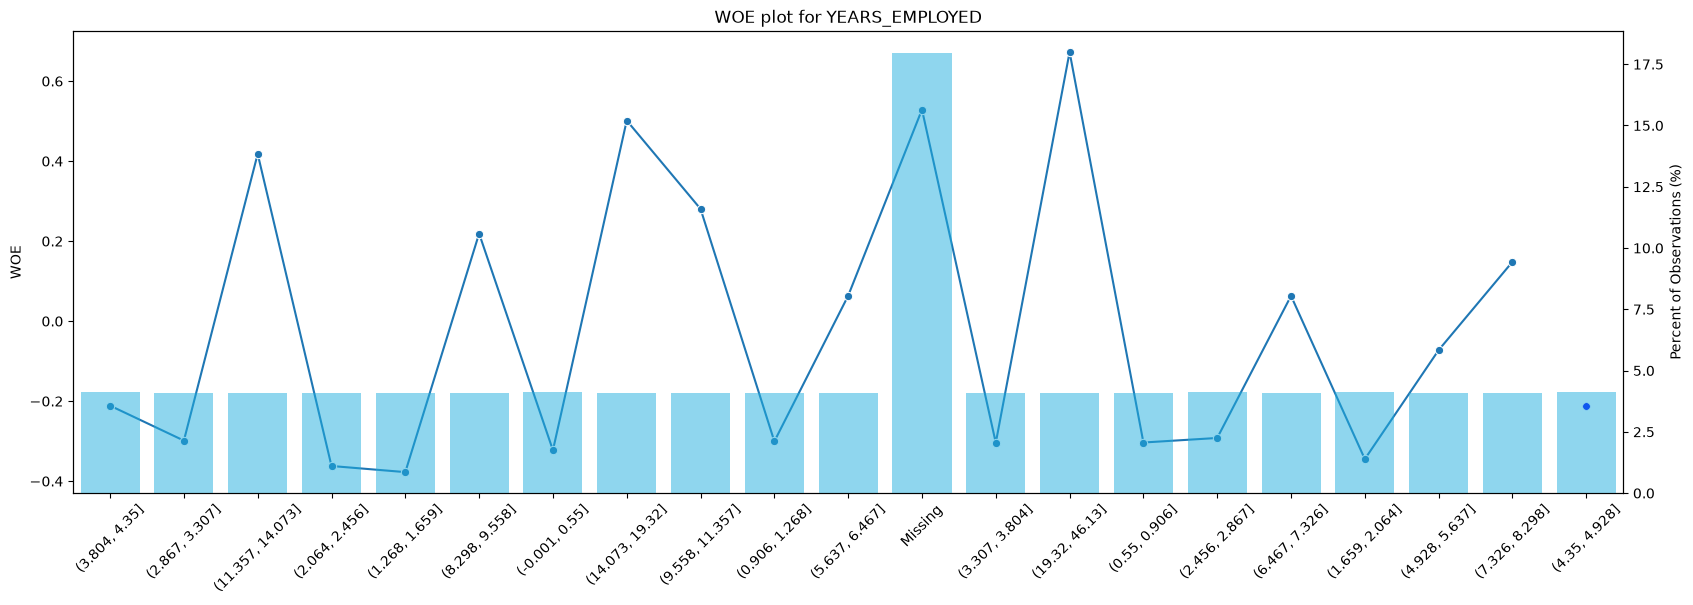

IV for TERM_MONTHS with 19 numeric bins: 0.2813


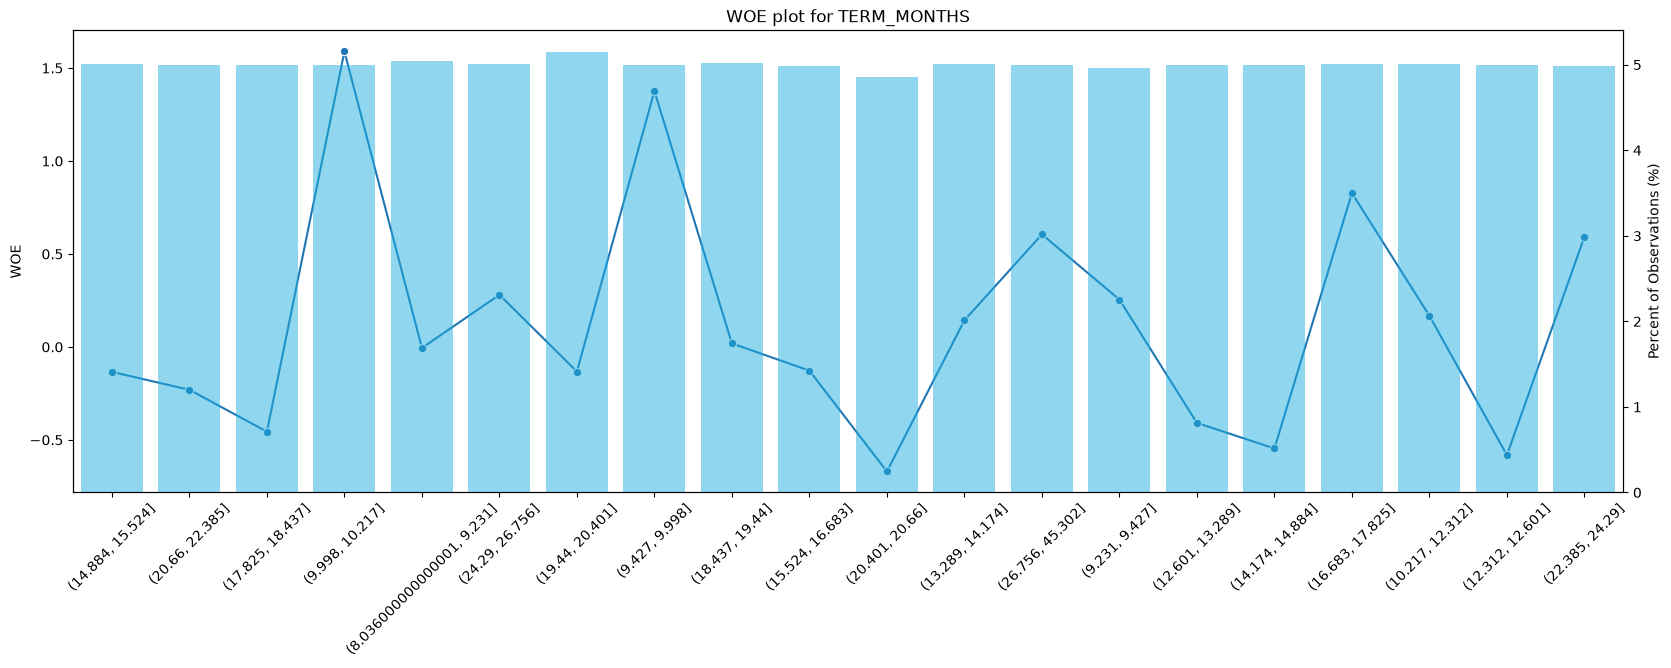

In [23]:
def woe_iv_plot(data, variable_name):
    variable_data = woe_iv(data)
    print('IV for', variable_name, 'with', variable_data.shape[0]-1, 'numeric bins:', round(variable_data.loc[0,'total_IV'],4))
    fig, ax1 = plt.subplots(figsize=(20,6))
    if variable_data['Bin_Range'].isin(['Missing']).sum() > 0:
        sns.lineplot(data = variable_data['WOE'].iloc[0:-1], marker='o', ax=ax1)
    else:
        sns.lineplot(data = variable_data['WOE'], marker='o', ax=ax1)
    plt.xticks(rotation=45)
    if variable_data['Bin_Range'].isin(['Missing']).sum() > 0:
        last_point = len(variable_data['WOE']) - 1
        sns.scatterplot(x=[last_point], y=[variable_data['WOE'][last_point]], color='b', s=30, ax=ax1)
    ax2 = ax1.twinx()
    total_count = variable_data['Count'].sum()
    variable_data['Percent'] = (variable_data['Count'] / total_count) * 100
    sns.barplot(x = variable_data['Bin_Range'].astype(str), y = variable_data['Percent'], alpha=0.5, ax = ax2, color = 'deepskyblue')
    ax2.set_ylabel('Percent of Observations (%)')
    plt.title("WOE plot for " + variable_name)
    plt.show()

for variable in ['YEARS_EMPLOYED', 'TERM_MONTHS']:
    woe_iv_plot(fine_class(train, variable), variable)

### 4.2 Grouping: coarse classing (Week 10 and Week 11 labs)
`sc.woebin` builds the coarse bins automatically. It optimises IV, gives every bin at least 5% of applicants and creates a
missing bin, but **it does not force a monotonic trend** (Week 11 lab note). Following Week 10 Ex Q3, every numeric
variable is checked for a monotonic bad rate, and the ones that break the trend get adjusted `breaks_list` bin edges.

**Note on sign:** scorecardpy defines WOE the other way round from the Week 10 function:
**scorecardpy WOE = ln(% bads / % goods)**, so a *positive* WOE means a *riskier* bin. The IV is the same either way.

In [24]:
bins_auto = sc.woebin(train[screened + ['TARGET']], y='TARGET')

def is_monotonic(b):
    r = b.loc[b['bin'] != 'missing', 'badprob'].values
    d = np.diff(r)
    return len(r) < 3 or bool((d >= 0).all() or (d <= 0).all())

auto_summary = pd.DataFrame([dict(variable=k, IV_coarse=v['total_iv'].iloc[0], n_bins=len(v), monotonic=is_monotonic(v),
                                  numeric=pd.api.types.is_numeric_dtype(train[k])) for k, v in bins_auto.items()])
auto_summary = auto_summary.sort_values('IV_coarse', ascending=False).reset_index(drop=True)
print('not monotonic (numeric):', auto_summary.query('~monotonic and numeric')['variable'].tolist())
auto_summary.round(4)

[INFO] creating woe binning ...


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: UserWarning: Could not infer format, so 

not monotonic (numeric): ['TERM_MONTHS', 'CREDIT_TO_GOODS', 'AMT_ANNUITY', 'ELEVATORS_AVG', 'BUR_MAX_CREDIT', 'REGION_POPULATION_RELATIVE', 'NONLIVINGAREA_AVG', 'BUR_N_ACTIVE', 'FLOORSMIN_MEDI']


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/woebin.py:414: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({'good':sum, 'bad':sum}).reset_index()\
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/woebin.py:414: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({'good':sum, 'bad':sum}).reset_index()\
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/woebin.py:414: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavio

,variable,IV_coarse,n_bins,monotonic,numeric
0,TERM_MONTHS,0.2022,5,False,True
1,EXT_SOURCE_1,0.1405,6,True,True
2,YEARS_EMPLOYED,0.1222,5,True,True
3,BUR_DEBT_TO_CREDIT,0.1043,5,True,True
4,AGE_YEARS,0.0973,4,True,True
5,BUR_SHARE_ACTIVE,0.0971,5,True,True
6,OCCUPATION_TYPE,0.0904,4,True,False
7,ORGANIZATION_TYPE,0.0834,4,True,False
8,BUR_HISTORY_YEARS,0.0808,5,True,True
9,NAME_INCOME_TYPE,0.0720,4,True,False


In [25]:
# show the automatic bins of the variables that are not monotonic
for v in auto_summary.query('~monotonic and numeric')['variable']:
    display(bins_auto[v][['variable','bin','count','count_distr','badprob','woe','total_iv']].round(4))

,variable,bin,count,count_distr,badprob,woe,total_iv
0,TERM_MONTHS,"[-inf,9.5)",9166,0.1184,0.0733,-0.2344,0.2022
1,TERM_MONTHS,"[9.5,10.5)",7392,0.0955,0.0230,-1.4466,0.2022
2,TERM_MONTHS,"[10.5,20.0)",40387,0.5217,0.1059,0.1689,0.2022
3,TERM_MONTHS,"[20.0,21.5)",8543,0.1104,0.1440,0.5198,0.2022
4,TERM_MONTHS,"[21.5,inf)",11920,0.1540,0.0579,-0.4872,0.2022


,variable,bin,count,count_distr,badprob,woe,total_iv
0,CREDIT_TO_GOODS,"[-inf,1.01)",24961,0.3225,0.0862,-0.0583,0.0541
1,CREDIT_TO_GOODS,"[1.01,1.08)",6714,0.0867,0.0564,-0.5139,0.0541
2,CREDIT_TO_GOODS,"[1.08,1.11)",6494,0.0839,0.0827,-0.1039,0.0541
3,CREDIT_TO_GOODS,"[1.11,1.1400000000000001)",7605,0.0982,0.0706,-0.2749,0.0541
4,CREDIT_TO_GOODS,"[1.1400000000000001,1.2400000000000002)",16798,0.2170,0.0950,0.0478,0.0541
5,CREDIT_TO_GOODS,"[1.2400000000000002,inf)",14836,0.1917,0.1239,0.3463,0.0541


,variable,bin,count,count_distr,badprob,woe,total_iv
0,AMT_ANNUITY,"[-inf,12000.0)",15004,0.1938,0.0685,-0.3073,0.0354
1,AMT_ANNUITY,"[12000.0,16000.0)",15360,0.1984,0.0801,-0.1388,0.0354
2,AMT_ANNUITY,"[16000.0,21000.0)",18684,0.2414,0.1014,0.1209,0.0354
3,AMT_ANNUITY,"[21000.0,23000.0)",7193,0.0929,0.1218,0.3268,0.0354
4,AMT_ANNUITY,"[23000.0,inf)",21167,0.2734,0.0949,0.0474,0.0354


,variable,bin,count,count_distr,badprob,woe,total_iv
0,ELEVATORS_AVG,missing,43439,0.5612,0.1007,0.1129,0.0264
1,ELEVATORS_AVG,"[-inf,0.02)",21259,0.2746,0.0857,-0.0654,0.0264
2,ELEVATORS_AVG,"[0.02,0.11)",4057,0.0524,0.0670,-0.3306,0.0264
3,ELEVATORS_AVG,"[0.11,0.21)",4546,0.0587,0.0719,-0.2550,0.0264
4,ELEVATORS_AVG,"[0.21,inf)",4107,0.0531,0.0594,-0.4596,0.0264


,variable,bin,count,count_distr,badprob,woe,total_iv
0,BUR_MAX_CREDIT,missing,11808,0.1525,0.1128,0.2400,0.0257
1,BUR_MAX_CREDIT,"[-inf,100000.0)",9897,0.1279,0.1004,0.1100,0.0257
2,BUR_MAX_CREDIT,"[100000.0,250000.0)",16585,0.2143,0.0797,-0.1447,0.0257
3,BUR_MAX_CREDIT,"[250000.0,950000.0)",24808,0.3205,0.0917,0.0099,0.0257
4,BUR_MAX_CREDIT,"[950000.0,2500000.0)",10406,0.1344,0.0852,-0.0708,0.0257
5,BUR_MAX_CREDIT,"[2500000.0,inf)",3904,0.0504,0.0584,-0.4778,0.0257


,variable,bin,count,count_distr,badprob,woe,total_iv
0,REGION_POPULATION_RELATIVE,"[-inf,0.007)",8573,0.1108,0.1025,0.1330,0.0244
1,REGION_POPULATION_RELATIVE,"[0.007,0.02)",36638,0.4733,0.0923,0.0170,0.0244
2,REGION_POPULATION_RELATIVE,"[0.02,0.021)",3883,0.0502,0.1262,0.3674,0.0244
3,REGION_POPULATION_RELATIVE,"[0.021,0.032)",19744,0.2551,0.0881,-0.0343,0.0244
4,REGION_POPULATION_RELATIVE,"[0.032,inf)",8570,0.1107,0.0637,-0.3851,0.0244


,variable,bin,count,count_distr,badprob,woe,total_iv
0,NONLIVINGAREA_AVG,missing,44712,0.5776,0.1002,0.1072,0.0216
1,NONLIVINGAREA_AVG,"[-inf,0.004)",17137,0.2214,0.0823,-0.1093,0.0216
2,NONLIVINGAREA_AVG,"[0.004,0.012)",4243,0.0548,0.0716,-0.2592,0.0216
3,NONLIVINGAREA_AVG,"[0.012,0.036000000000000004)",4740,0.0612,0.0863,-0.0574,0.0216
4,NONLIVINGAREA_AVG,"[0.036000000000000004,inf)",6576,0.0850,0.0663,-0.3425,0.0216


,variable,bin,count,count_distr,badprob,woe,total_iv
0,BUR_N_ACTIVE,"[-inf,1.0)",24081,0.3111,0.0880,-0.0354,0.0209
1,BUR_N_ACTIVE,"[1.0,3.0)",33031,0.4267,0.0833,-0.0965,0.0209
2,BUR_N_ACTIVE,"[3.0,5.0)",14334,0.1852,0.0964,0.0647,0.0209
3,BUR_N_ACTIVE,"[5.0,inf)",5962,0.0770,0.1318,0.4176,0.0209


,variable,bin,count,count_distr,badprob,woe,total_iv
0,FLOORSMIN_MEDI,missing,54313,0.7016,0.0968,0.0695,0.0171
1,FLOORSMIN_MEDI,"[-inf,0.06)",5013,0.0648,0.0758,-0.1983,0.0171
2,FLOORSMIN_MEDI,"[0.06,0.22)",11190,0.1446,0.0853,-0.0706,0.0171
3,FLOORSMIN_MEDI,"[0.22,inf)",6892,0.0890,0.0646,-0.3709,0.0171


**Adjusted bin edges.** For each non-monotonic numeric variable, adjacent bins whose bad rates cross are merged, so
that the bad rate rises or falls steadily (Week 10 Ex Q3). The resulting edges are given to `sc.woebin` as a `breaks_list`.
The comment next to each one gives the business reading.

In [26]:
breaks_adj = {
    # merge bins whose bad rates cross, so the trend runs one way (Week 10 Ex Q3)
    'CREDIT_TO_GOODS':              [1.14, 1.25],             # financing more than the procedure price -> riskier
    'AMT_CREDIT':                   [110000, 180000, 280000], # larger loan -> riskier
    'AMT_ANNUITY':                  [13000, 16000],           # larger monthly instalment -> riskier
    'REGION_POPULATION_RELATIVE':   [0.021, 0.032],           # more populated region -> safer
    'YEARS_BEGINEXPLUATATION_MEDI': [0.977, 0.988],           # newer building -> safer
    'BUR_MAX_CREDIT':               [100000, 2450000],        # larger past credits elsewhere -> safer
    # U-shaped: kept as 3 bins, one of which breaks the trend (Week 10 DIY Q1 approach)
    'TERM_MONTHS':                  [10.5, 21.5],             # short (under ~10m) and long (22m+) loans safer than 11-21m
}

declared_breaks_adj = breaks_adj.copy()
breaks_adj = {k: v for k, v in declared_breaks_adj.items() if k in screened}
print('Applied manual bin breaks:', list(breaks_adj))
print('Skipped (not IV-screened in this run):', sorted(set(declared_breaks_adj) - set(breaks_adj)))
bins = sc.woebin(train[screened + ['TARGET']], y='TARGET', breaks_list=breaks_adj) if breaks_adj else bins_auto

coarse_summary = pd.DataFrame([dict(variable=k, IV_coarse=v['total_iv'].iloc[0], n_bins=len(v), monotonic=is_monotonic(v))
                               for k, v in bins.items()]).sort_values('IV_coarse', ascending=False).reset_index(drop=True)
coarse_summary['strength'] = coarse_summary['IV_coarse'].map(iv_strength)
print('still not monotonic:', coarse_summary.query('~monotonic')['variable'].tolist())

# second screen: drop variables whose IV fell below 0.02 after grouping
coarse_kept = coarse_summary.loc[coarse_summary['IV_coarse'] >= 0.02, 'variable'].tolist()
print(f'{len(coarse_kept)} variables with coarse IV >= 0.02')
coarse_summary.round(4)

Applied manual bin breaks: ['CREDIT_TO_GOODS', 'AMT_CREDIT', 'AMT_ANNUITY', 'REGION_POPULATION_RELATIVE', 'YEARS_BEGINEXPLUATATION_MEDI', 'BUR_MAX_CREDIT', 'TERM_MONTHS']
Skipped (not IV-screened in this run): []
[INFO] creating woe binning ...


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: UserWarning: Could not infer format, so 

still not monotonic: ['TERM_MONTHS', 'ELEVATORS_AVG', 'NONLIVINGAREA_AVG', 'BUR_N_ACTIVE', 'FLOORSMIN_MEDI']
36 variables with coarse IV >= 0.02


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/woebin.py:442: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binning_1bst_brk = binning_1bst_brk.groupby(['variable', 'bstbin'], group_keys=False)\
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/woebin.py:443: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({'good':sum, 'bad':sum}).reset_index().assign(bin=lambda x: x['bstbin'])\
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/woebin.py:443: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future versio

,variable,IV_coarse,n_bins,monotonic,strength
0,EXT_SOURCE_1,0.1405,6,True,medium
1,TERM_MONTHS,0.1339,3,False,medium
2,YEARS_EMPLOYED,0.1222,5,True,medium
3,BUR_DEBT_TO_CREDIT,0.1043,5,True,medium
4,AGE_YEARS,0.0973,4,True,weak
5,BUR_SHARE_ACTIVE,0.0971,5,True,weak
6,OCCUPATION_TYPE,0.0904,4,True,weak
7,ORGANIZATION_TYPE,0.0834,4,True,weak
8,BUR_HISTORY_YEARS,0.0808,5,True,weak
9,NAME_INCOME_TYPE,0.0720,4,True,weak


In [27]:
# NEW — coarse-grouping verification
assert set(coarse_kept).issubset(set(bins))
assert np.isfinite(coarse_summary['IV_coarse']).all(), 'Invalid coarse-class IV'
assert all(coarse_summary.set_index('variable').loc[coarse_kept, 'IV_coarse'] >= .02)
print('COARSE IV AUDIT: training-derived bins, finite IV and screened membership confirmed')
print('Non-monotonic numeric exceptions (review for explainability):',
      coarse_summary.loc[~coarse_summary['monotonic'], 'variable'].tolist())

COARSE IV AUDIT: training-derived bins, finite IV and screened membership confirmed
Non-monotonic numeric exceptions (review for explainability): ['TERM_MONTHS', 'ELEVATORS_AVG', 'NONLIVINGAREA_AVG', 'BUR_N_ACTIVE', 'FLOORSMIN_MEDI']


In [28]:
# adjusted bins for the variables that were changed
for v in breaks_adj:
    if v in bins:
        display(bins[v][['variable','bin','count','count_distr','badprob','woe','total_iv']].round(4))

,variable,bin,count,count_distr,badprob,woe,total_iv
0,CREDIT_TO_GOODS,"[-inf,1.14)",45774,0.5913,0.0788,-0.1569,0.0406
1,CREDIT_TO_GOODS,"[1.14,1.25)",16798,0.2170,0.0950,0.0478,0.0406
2,CREDIT_TO_GOODS,"[1.25,inf)",14836,0.1917,0.1239,0.3463,0.0406


,variable,bin,count,count_distr,badprob,woe,total_iv
0,AMT_CREDIT,"[-inf,110000.0)",4556,0.0589,0.0558,-0.5271,0.0335
1,AMT_CREDIT,"[110000.0,180000.0)",9158,0.1183,0.0681,-0.3132,0.0335
2,AMT_CREDIT,"[180000.0,280000.0)",23034,0.2976,0.0869,-0.0495,0.0335
3,AMT_CREDIT,"[280000.0,inf)",40660,0.5253,0.1023,0.1301,0.0335


,variable,bin,count,count_distr,badprob,woe,total_iv
0,AMT_ANNUITY,"[-inf,13000.0)",18433,0.2381,0.0704,-0.2779,0.0287
1,AMT_ANNUITY,"[13000.0,16000.0)",11931,0.1541,0.0805,-0.1336,0.0287
2,AMT_ANNUITY,"[16000.0,inf)",47044,0.6077,0.1016,0.1229,0.0287


,variable,bin,count,count_distr,badprob,woe,total_iv
0,REGION_POPULATION_RELATIVE,"[-inf,0.021)",49094,0.6342,0.0968,0.0691,0.0174
1,REGION_POPULATION_RELATIVE,"[0.021,0.032)",19744,0.2551,0.0881,-0.0343,0.0174
2,REGION_POPULATION_RELATIVE,"[0.032,inf)",8570,0.1107,0.0637,-0.3851,0.0174


,variable,bin,count,count_distr,badprob,woe,total_iv
0,YEARS_BEGINEXPLUATATION_MEDI,missing,39846,0.5148,0.1017,0.1239,0.0213
1,YEARS_BEGINEXPLUATATION_MEDI,"[-inf,0.977)",9962,0.1287,0.0874,-0.0430,0.0213
2,YEARS_BEGINEXPLUATATION_MEDI,"[0.977,0.988)",20737,0.2679,0.0791,-0.1524,0.0213
3,YEARS_BEGINEXPLUATATION_MEDI,"[0.988,inf)",6863,0.0887,0.0692,-0.2964,0.0213


,variable,bin,count,count_distr,badprob,woe,total_iv
0,BUR_MAX_CREDIT,missing,11808,0.1525,0.1128,0.2400,0.022
1,BUR_MAX_CREDIT,"[-inf,100000.0)",9897,0.1279,0.1004,0.1100,0.022
2,BUR_MAX_CREDIT,"[100000.0,2450000.0)",51618,0.6668,0.0865,-0.0544,0.022
3,BUR_MAX_CREDIT,"[2450000.0,inf)",4085,0.0528,0.0602,-0.4452,0.022


,variable,bin,count,count_distr,badprob,woe,total_iv
0,TERM_MONTHS,"[-inf,10.5)",16558,0.2139,0.0509,-0.6242,0.1339
1,TERM_MONTHS,"[10.5,21.5)",48930,0.6321,0.1125,0.2373,0.1339
2,TERM_MONTHS,"[21.5,inf)",11920,0.1540,0.0579,-0.4872,0.1339


## Part 5. Logistic regression and model performance
### 5.1 Logistic regression with WOE encoding (Week 11 lab)
`sc.woebin_ply` replaces each value with the WOE of its bin. Before fitting:
* **Correlation between WOE variables:** same 0.8 rule as Week 9, keeping the variable with the higher IV.
* **Variable selection** (in the spirit of Week 9 DIY Q3): forward selection. At each step add the variable that raises the
  training **Gini** the most, and stop at 15 variables or when the gain drops below 0.002. A variable is accepted only if
  **every coefficient stays above 0.1**. With scorecardpy's WOE (positive = riskier), a negative coefficient would make the
  points run against the bins, and a coefficient near 0 means a variable has been made redundant by a similar one added
  later, which leaves it with the same points in every bin.

In [29]:
# UPDATED — WOE fit on train; use VALIDATION, never test, during forward selection.
train_woe = sc.woebin_ply(train[coarse_kept + ['TARGET']], bins)
valid_woe = sc.woebin_ply(valid[coarse_kept + ['TARGET']], bins)
# Scorecardpy may return a fresh RangeIndex; attach input indexes to preserve applicant alignment.
train_woe.index, valid_woe.index = train.index, valid.index
y_train, y_valid = train_woe['TARGET'], valid_woe['TARGET']

iv_of = coarse_summary.set_index('variable')['IV_coarse']
woe_cols = sorted([c for c in train_woe.columns if c.endswith('_woe')],
                  key=lambda c: -iv_of[c[:-4]])
wcor = train_woe[woe_cols].corr().abs()
candidates = []
for c in woe_cols:
    if all(wcor.loc[c, k] <= 0.8 for k in candidates):
        candidates.append(c)
print(f'{len(woe_cols)} WOE variables -> {len(candidates)} candidates after redundancy screening')

def gini(y, p):
    return 2 * metrics.roc_auc_score(y, p) - 1

def fit(cols):
    m = linear_model.LogisticRegression(max_iter=1000)
    return m.fit(train_woe[cols], y_train)

MIN_COEF = 0.1
selected, path, best_g = [], [], 0.0
while len(selected) < 15:
    best = None
    for c in candidates:
        if c in selected:
            continue
        trial = selected + [c]
        candidate_model = fit(trial)
        if (candidate_model.coef_[0] < MIN_COEF).any():
            continue
        val_g = gini(y_valid, candidate_model.predict_proba(valid_woe[trial])[:, 1])
        if best is None or val_g > best[1]:
            best = (c, val_g, candidate_model)
    if best is None or best[1] - best_g < 0.002:
        break
    c, best_g, chosen_lr = best
    selected.append(c)
    path.append(dict(step=len(selected), added=c[:-4],
                     gini_train=gini(y_train, chosen_lr.predict_proba(train_woe[selected])[:, 1]),
                     gini_validation=best_g))
path = pd.DataFrame(path)
assert selected, 'No variables passed forward selection; re-evaluate positive coefficient rule.'
path.to_csv('g7_forward_selection_validation.csv', index=False)
display(path.round(4))

[INFO] converting into woe values ...


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this pac

[INFO] converting into woe values ...


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this pac

36 WOE variables -> 33 candidates after redundancy screening


,step,added,gini_train,gini_validation
0,1,BUR_DEBT_TO_CREDIT,0.1777,0.1946
1,2,EXT_SOURCE_1,0.2605,0.2875
2,3,TERM_MONTHS,0.3169,0.3330
3,4,YEARS_EMPLOYED,0.3504,0.3614
4,5,BUR_N_ACTIVE,0.3592,0.3766
5,6,BUR_SHARE_OVERDUE,0.3667,0.3865
6,7,YEARS_PHONE_CHANGE,0.3782,0.3962
7,8,REGION_RATING_CLIENT_W_CITY,0.3907,0.4041
8,9,NAME_EDUCATION_TYPE,0.4014,0.4110
9,10,AMT_CREDIT,0.4063,0.4176


## Part 6. Model tuning
What was compared (test Gini decides; train vs test shows overfitting):
1. **Number of variables:** the forward-selection path above shows where extra variables stop adding much.
2. **Automatic vs adjusted bins:** `sc.woebin` defaults against the monotonic `breaks_list` version.
3. **`class_weight='balanced'`** (Week 9 lab): it re-weights the bads but distorts the probabilities, so the score no longer
   lines up with the 600 = 5% PD scaling.
4. **All candidate variables** against the selected ones.

In [30]:
# UPDATED — compare model candidates using VALIDATION, not the final test set.
def validation_gini(bins_used, cols, **lr_args):
    names = [c[:-4] for c in cols]
    trw = sc.woebin_ply(train[names + ['TARGET']], bins_used)
    vaw = sc.woebin_ply(valid[names + ['TARGET']], bins_used)
    m = linear_model.LogisticRegression(max_iter=1000, **lr_args).fit(trw[cols], trw['TARGET'])
    p_tr = m.predict_proba(trw[cols])[:, 1]
    p_va = m.predict_proba(vaw[cols])[:, 1]
    return dict(n_vars=len(cols), gini_train=gini(trw['TARGET'], p_tr),
                gini_validation=gini(vaw['TARGET'], p_va),
                wrong_sign=int((m.coef_[0] <= 0).sum()),
                mean_predicted_PD_validation=p_va.mean(),
                validation_bad_rate=float(vaw['TARGET'].mean()))

tuning = pd.DataFrame({
    'Selected variables, adjusted bins (proposed)': validation_gini(bins, selected),
    'Selected variables, automatic bins':           validation_gini(bins_auto, selected),
    'First 5 selected variables':                   validation_gini(bins, selected[:5]),
    'First 10 selected variables':                  validation_gini(bins, selected[:10]),
    'All candidate variables':                      validation_gini(bins, candidates),
    "Selected + class_weight='balanced'":           validation_gini(bins, selected, class_weight='balanced'),
}).T
tuning['PD_calibration_gap'] = (tuning['mean_predicted_PD_validation'] - tuning['validation_bad_rate']).abs()
tuning.to_csv('g7_tuning_validation.csv')
display(tuning.round(4))

[INFO] converting into woe values ...


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this pac

[INFO] converting into woe values ...


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this pac

[INFO] converting into woe values ...


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this pac

... (11 outputs left out)

/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this pac

[INFO] converting into woe values ...


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this pac

,n_vars,gini_train,gini_validation,wrong_sign,mean_predicted_PD_validation,validation_bad_rate,PD_calibration_gap
"Selected variables, adjusted bins (proposed)",14.0,0.4238,0.4352,0.0,0.0906,0.0909,0.0003
"Selected variables, automatic bins",14.0,0.4313,0.4372,0.0,0.0906,0.0909,0.0003
First 5 selected variables,5.0,0.3592,0.3766,0.0,0.0907,0.0909,0.0002
First 10 selected variables,10.0,0.4063,0.4176,0.0,0.0904,0.0909,0.0005
All candidate variables,33.0,0.4506,0.4357,4.0,0.0906,0.0909,0.0003
Selected + class_weight='balanced',14.0,0.4239,0.4355,0.0,0.4437,0.0909,0.3528


In [31]:
# NEW — explicit decision audit BEFORE fitting/assessing the final test model.
chosen_model_description = 'Selected variables, adjusted bins (proposed)'
proposed = tuning.loc[chosen_model_description]
eligible = tuning[(tuning['wrong_sign'] == 0) & (tuning['PD_calibration_gap'] <= 0.03)]
if not eligible.empty:
    top_eligible = eligible.sort_values('gini_validation', ascending=False).iloc[0]
    top_name = eligible.sort_values('gini_validation', ascending=False).index[0]
    gap = float(top_eligible['gini_validation'] - proposed['gini_validation'])
    print('Best eligible validation model:', top_name,
          '| validation Gini advantage over proposed:', round(gap, 4))
    if gap > 0.02:
        print('GROUP REVIEW REQUIRED: reconsider the proposed scorecard before reporting final test results.')
print('Proposed model locked for this run:', chosen_model_description)
print('Chosen predictor count:', len(selected))

Best eligible validation model: Selected variables, automatic bins | validation Gini advantage over proposed: 0.002
Proposed model locked for this run: Selected variables, adjusted bins (proposed)
Chosen predictor count: 14


**Reading the tuning table**
* **Gains flatten after about 10 variables**, so 15 is a reasonable stopping point.
* **Automatic bins score slightly higher** than the adjusted ones, because `sc.woebin` is free to follow every wiggle in
  the data. The adjusted, monotonic bins are kept because each one has a business explanation and is more stable on
  new applicants. A small Gini cost for an explainable scorecard is the trade-off to state.
* **All candidate variables** gives the highest Gini, but at least one coefficient has the wrong sign, so its points would
  contradict its own bins. It is also harder to explain and maintain.
* **`class_weight='balanced'`** barely changes the ranking (Gini), but the average predicted PD jumps far above the real
  bad rate. The scorecard scaling (600 = 5% PD) and the expected-default calculation both need true probabilities, so it is not used.

In [32]:
# UPDATED — AFTER model choice, fit on train and evaluate on untouched test data.
test_woe = sc.woebin_ply(test[coarse_kept + ['TARGET']], bins)
test_woe.index = test.index
y_test = test_woe['TARGET']
X_train, X_valid, X_test = train_woe[selected], valid_woe[selected], test_woe[selected]
lr = linear_model.LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
coefs = pd.Series(np.concatenate([lr.intercept_, lr.coef_[0]]),
                  index=np.concatenate([['intercept'], lr.feature_names_in_]))
coef_table = pd.DataFrame({'coef': coefs, 'IV': [np.nan] + [iv_of[c[:-4]] for c in selected]})
assert np.isfinite(lr.coef_).all() and np.isfinite(lr.intercept_).all()
assert len(lr.feature_names_in_) == len(selected)
display(coef_table.round(4))

[INFO] converting into woe values ...


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this pac

,coef,IV
intercept,-2.3035,NaN
BUR_DEBT_TO_CREDIT_woe,0.2800,0.1043
EXT_SOURCE_1_woe,0.6838,0.1405
TERM_MONTHS_woe,0.6879,0.1339
YEARS_EMPLOYED_woe,0.6575,0.1222
BUR_N_ACTIVE_woe,1.0612,0.0209
BUR_SHARE_OVERDUE_woe,0.9405,0.0386
YEARS_PHONE_CHANGE_woe,0.6317,0.0568
REGION_RATING_CLIENT_W_CITY_woe,0.8319,0.0444
NAME_EDUCATION_TYPE_woe,0.9132,0.0394


### 5.2 Scorecard and model performance (Week 11 lab)
Same scaling as the lab: **600 points = odds of 1:19 (bad:good), i.e. a 5% probability of default**, and **20 points
doubles the odds (PDO = 20)**. `basepoints_eq0=True` spreads the base points across the variables.

In [33]:
# UPDATED — one consistent scorecard for train / validation / test.
card = sc.scorecard(bins, lr, X_train.columns, points0=600, odds0=1/19,
                    pdo=20, basepoints_eq0=True)
scorecard_table = pd.concat(card.values(), ignore_index=True).query(
    "variable != 'basepoints'")[['variable', 'bin', 'points']]
scorecard_table.to_csv('g7_scorecard_points.csv', index=False)
train_score = sc.scorecard_ply(train, card)
valid_score = sc.scorecard_ply(valid, card)
test_score = sc.scorecard_ply(test, card)
train_score.index, valid_score.index, test_score.index = train.index, valid.index, test.index
print('Score range:', int(min(train_score.score.min(), valid_score.score.min(), test_score.score.min())),
      'to', int(max(train_score.score.max(), valid_score.score.max(), test_score.score.max())))
assert len(train_score)==len(train) and len(valid_score)==len(valid) and len(test_score)==len(test)
display(scorecard_table)

/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/scorecard.py:353: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dat_score.loc[:,'score'] = card_basepoints + dat_score.sum(axis=1)
/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/scorecard.py:353: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dat_score.loc[:,'score'] = card_basepoints + dat_score.sum(axis=1)


Score range: 497 to 676


/opt/anaconda3/envs/IS453/lib/python3.11/site-packages/scorecardpy/scorecard.py:353: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dat_score.loc[:,'score'] = card_basepoints + dat_score.sum(axis=1)


,variable,bin,points
1,BUR_DEBT_TO_CREDIT,missing,40.0
2,BUR_DEBT_TO_CREDIT,"[-inf,0.15000000000000002)",44.0
3,BUR_DEBT_TO_CREDIT,"[0.15000000000000002,0.4)",43.0
4,BUR_DEBT_TO_CREDIT,"[0.4,0.65)",40.0
5,BUR_DEBT_TO_CREDIT,"[0.65,inf)",37.0
6,EXT_SOURCE_1,missing,40.0
7,EXT_SOURCE_1,"[-inf,0.22)",26.0
8,EXT_SOURCE_1,"[0.22,0.42)",37.0
9,EXT_SOURCE_1,"[0.42,0.5)",46.0
10,EXT_SOURCE_1,"[0.5,0.64)",51.0


In [34]:
# bins of the final model with their points (the table for the slides)
final_bins = pd.concat([bins[c[:-4]] for c in selected], ignore_index=True)
final_bins = final_bins.merge(scorecard_table, on=['variable', 'bin'], how='left')
final_bins = final_bins[['variable', 'bin', 'count', 'count_distr', 'badprob', 'woe', 'total_iv', 'points']]
final_bins.to_csv('g7_final_bins_and_points.csv', index=False)
final_bins.round(4)

,variable,bin,count,count_distr,badprob,woe,total_iv,points
0,BUR_DEBT_TO_CREDIT,missing,12051,0.1557,0.1128,0.2397,0.1043,40.0
1,BUR_DEBT_TO_CREDIT,"[-inf,0.15000000000000002)",29000,0.3746,0.0652,-0.3598,0.1043,44.0
2,BUR_DEBT_TO_CREDIT,"[0.15000000000000002,0.4)",15375,0.1986,0.0783,-0.1631,0.1043,43.0
3,BUR_DEBT_TO_CREDIT,"[0.4,0.65)",11895,0.1537,0.1047,0.1560,0.1043,40.0
4,BUR_DEBT_TO_CREDIT,"[0.65,inf)",9087,0.1174,0.1472,0.5461,0.1043,37.0
5,EXT_SOURCE_1,missing,44304,0.5723,0.0957,0.0560,0.1405,40.0
6,EXT_SOURCE_1,"[-inf,0.22)",4100,0.0530,0.1771,0.7661,0.1405,26.0
7,EXT_SOURCE_1,"[0.22,0.42)",9791,0.1265,0.1094,0.2054,0.1405,37.0
8,EXT_SOURCE_1,"[0.42,0.5)",4069,0.0526,0.0754,-0.2034,0.1405,46.0
9,EXT_SOURCE_1,"[0.5,0.64)",6694,0.0865,0.0592,-0.4641,0.1405,51.0


In [35]:
# NEW — verify scorecard points can be reconciled with final training-derived bins.
assert not scorecard_table['points'].isna().any(), 'Missing points in scorecard'
assert not final_bins['points'].isna().any(), 'A final model bin has no points'
assert set(v[:-4] for v in selected) == set(scorecard_table['variable'])
print('SCORECARD AUDIT: all selected predictor bins have points')

SCORECARD AUDIT: all selected predictor bins have points


**Ranking performance (AUC, Gini, KS)** on train and test. Similar values on both mean the model is not overfitting.

In [36]:
def ks_stat(y, score):
    d = pd.DataFrame({'y': np.asarray(y), 's': np.asarray(score)}).groupby('s')['y'].agg(
        bads='sum', n='size').cumsum()
    cum_bad = d['bads'] / d['bads'].iloc[-1]
    cum_good = (d['n'] - d['bads']) / (d['n'] - d['bads']).iloc[-1]
    return (cum_bad - cum_good).abs().max()

perf = pd.DataFrame({
    'AUC': [metrics.roc_auc_score(y_train, -train_score.score),
            metrics.roc_auc_score(y_valid, -valid_score.score),
            metrics.roc_auc_score(y_test, -test_score.score)],
    'Gini': [gini(y_train, -train_score.score),
             gini(y_valid, -valid_score.score),
             gini(y_test, -test_score.score)],
    'KS': [ks_stat(y_train, train_score.score),
           ks_stat(y_valid, valid_score.score),
           ks_stat(y_test, test_score.score)]},
    index=['train', 'validation', 'test'])
assert perf.notna().all().all()
perf.to_csv('g7_final_model_performance.csv')
display(perf.round(4))

,AUC,Gini,KS
train,0.7120,0.4240,0.3134
validation,0.7175,0.4349,0.3188
test,0.7139,0.4278,0.3091


In [37]:
# NEW — final discrimination vs probability-calibration audit; reporting only, not tuning.
pred_bad_train = lr.predict_proba(X_train)[:, 1]
pred_bad_valid = lr.predict_proba(X_valid)[:, 1]
pred_bad_test  = lr.predict_proba(X_test)[:, 1]
calibration_overview = pd.DataFrame({
    'sample': ['train', 'validation', 'test'],
    'observed_rate': [y_train.mean(), y_valid.mean(), y_test.mean()],
    'mean_model_probability': [pred_bad_train.mean(), pred_bad_valid.mean(), pred_bad_test.mean()],
    'brier_score': [metrics.brier_score_loss(y_train, pred_bad_train),
                    metrics.brier_score_loss(y_valid, pred_bad_valid),
                    metrics.brier_score_loss(y_test, pred_bad_test)],
}).set_index('sample')
calibration_overview['rate_gap'] = (calibration_overview.mean_model_probability -
                                   calibration_overview.observed_rate).abs()
display(calibration_overview.round(4))
calibration_overview.to_csv('g7_calibration_audit.csv')

,observed_rate,mean_model_probability,brier_score,rate_gap
sample,,,,
train,0.0909,0.0909,0.0783,0.0000
validation,0.0909,0.0906,0.0779,0.0003
test,0.0910,0.0908,0.0781,0.0002


**ROC and K-S curves.** For these curves a *defaulter* is the event the score is trying to catch, so a low score means
"predicted defaulter".
* **ROC curve (left):** working down from the lowest scores, the share of defaulters caught (y-axis) against the share
  of good payers wrongly caught with them (x-axis). The further the curve bows above the diagonal, the better the
  scorecard ranks applicants. The area under it is the AUC (0.5 = random, 1 = perfect).
* **K-S chart (right):** for every score, the share of all defaulters and the share of all good payers scoring at or
  below it. The K-S statistic is the widest gap between the two lines, i.e. the score where the scorecard separates
  goods from bads most strongly.

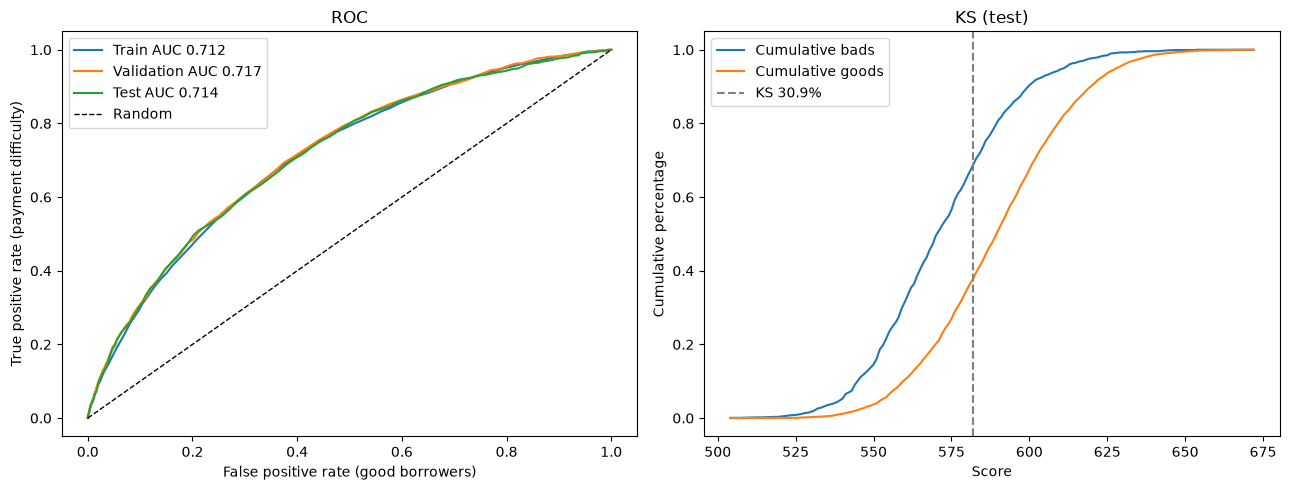

Test KS 30.91% at score 582


In [38]:
# UPDATED — final ROC and KS reporting (no further model decisions based on test).
fpr_tr, tpr_tr, _ = metrics.roc_curve(y_train, -train_score['score'].values)
fpr_va, tpr_va, _ = metrics.roc_curve(y_valid, -valid_score['score'].values)
fpr_te, tpr_te, _ = metrics.roc_curve(y_test, -test_score['score'].values)
ks_df = pd.DataFrame({'y': y_test.values, 'score': test_score['score'].values}).sort_values('score')
ks_df = ks_df.groupby('score')['y'].agg(bads='sum', n='size').cumsum()
ks_df['cum_bads'] = ks_df['bads'] / ks_df['bads'].iloc[-1]
ks_df['cum_goods'] = (ks_df['n'] - ks_df['bads']) / (ks_df['n'] - ks_df['bads']).iloc[-1]
ks_df['gap'] = ks_df['cum_bads'] - ks_df['cum_goods']
ks_score = ks_df['gap'].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr_tr, tpr_tr, label=f"Train AUC {perf.loc['train', 'AUC']:.3f}")
axes[0].plot(fpr_va, tpr_va, label=f"Validation AUC {perf.loc['validation', 'AUC']:.3f}")
axes[0].plot(fpr_te, tpr_te, label=f"Test AUC {perf.loc['test', 'AUC']:.3f}")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
axes[0].set_xlabel('False positive rate (good borrowers)')
axes[0].set_ylabel('True positive rate (payment difficulty)')
axes[0].set_title('ROC'); axes[0].legend()
axes[1].plot(ks_df.index, ks_df['cum_bads'], label='Cumulative bads')
axes[1].plot(ks_df.index, ks_df['cum_goods'], label='Cumulative goods')
axes[1].axvline(ks_score, ls='--', c='grey', label=f"KS {ks_df['gap'].max():.1%}")
axes[1].set_xlabel('Score'); axes[1].set_ylabel('Cumulative percentage')
axes[1].set_title('KS (test)'); axes[1].legend()
plt.tight_layout(); plt.savefig('g7_roc_ks_curves.png', dpi=150); plt.show()
print(f"Test KS {ks_df['gap'].max():.2%} at score {ks_score:.0f}")

**Score distribution** (Week 11 lab)

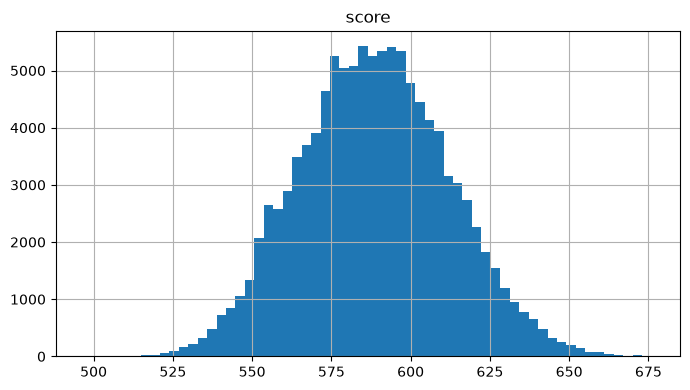

In [39]:
combined_score = pd.concat([train_score, valid_score, test_score], ignore_index=True)
combined_score.hist(figsize=(7, 4), bins=60)
plt.tight_layout()
plt.savefig('g7_score_distribution.png', dpi=150)
plt.show()

**PCC measures at a cutoff** (Week 11 lab `show_performance`). Applicants below the cutoff are predicted to be defaulters.

In [40]:
def show_performance(title, y_actual, predicted_list):
    cm = metrics.confusion_matrix(y_actual, predicted_list, labels=[0, 1])
    tp, fn, fp, tn = cm.ravel()
    labelled = pd.DataFrame(
        [[f'{tp:,}  (TP)', f'{fn:,}  (FN)'],
         [f'{fp:,}  (FP)', f'{tn:,}  (TN)']],
        index=['Actual: Good payer (0)', 'Actual: Payment difficulty (1)'],
        columns=['Predicted: Good payer (0)', 'Predicted: Payment difficulty (1)'])
    print(f'*** {title} ***')
    print(labelled.to_string())
    print(metrics.classification_report(y_actual, predicted_list, labels=[0, 1],
          target_names=['Good payer (0)', 'Payment difficulty (1)']))

def pcc_at(cutoff):
    show_performance(f'Train at {cutoff}', y_train,
                     (train_score['score'] < cutoff).astype(int).tolist())
    show_performance(f'Validation at {cutoff}', y_valid,
                     (valid_score['score'] < cutoff).astype(int).tolist())
    show_performance(f'Test at {cutoff}', y_test,
                     (test_score['score'] < cutoff).astype(int).tolist())

## Part 7. Cutoff, interest rate and profitability
### 7.1 Cutoff score and expected defaults (Week 11 lab)
For each cutoff: the approval rate, **expected defaults** from the score
(odds good:bad = 19 × 2^((score − 600)/20), PD = 1/(1 + odds)), and actual defaults among approved applicants.

In [41]:
def cutoff_table(score, y, cutoffs):
    rows = []
    for cutoff in cutoffs:
        approved = score['score'] >= cutoff
        odds = 19 * 2 ** ((score.loc[approved, 'score'] - 600) / 20)
        rows.append(dict(cutoff=cutoff, approved=int(approved.sum()),
                         approval_rate=approved.mean(),
                         expected_defaults=float((1 / (1 + odds)).sum()),
                         actual_defaults=int(y[approved].sum()),
                         bad_rate_approved=y[approved].mean()))
    return pd.DataFrame(rows)

lowest = int(min(train_score.score.min(), valid_score.score.min())) // 5 * 5
highest = int(max(train_score.score.quantile(.97), valid_score.score.quantile(.97)))
cutoffs = list(range(lowest, highest + 6, 5))
cutoff_train = cutoff_table(train_score, y_train, cutoffs)
cutoff_valid = cutoff_table(valid_score, y_valid, cutoffs)
print('Validation cutoff grid (outcome-based cutoff decisions must use this, not test):')
display(cutoff_valid[cutoff_valid.cutoff >= 540].round(4))

Validation cutoff grid (outcome-based cutoff decisions must use this, not test):


,cutoff,approved,approval_rate,expected_defaults,actual_defaults,bad_rate_approved
9,540,16349,0.9857,1436.3680,1428,0.0873
10,545,16124,0.9721,1373.1262,1355,0.0840
11,550,15845,0.9553,1303.8372,1287,0.0812
12,555,15416,0.9294,1210.7949,1186,0.0769
13,560,14718,0.8873,1078.2235,1059,0.0720
14,565,13933,0.8400,949.6817,933,0.0670
15,570,13010,0.7843,818.9546,794,0.0610
16,575,11920,0.7186,686.0076,676,0.0567
17,580,10662,0.6428,554.1774,548,0.0514
18,585,9356,0.5641,437.0892,418,0.0447


### 7.2 Profitability and interest rate
**Assumptions. Agree these as a group and state them on the slides:**

| Assumption | Value | Reason |
|---|---|---|
| Product interest rate (APR) | 15% | illustrative rate for an unsecured instalment loan |
| Cost of funds | 5% p.a. | bank's own borrowing cost |
| Loss given default (LGD) | 70% of the loan | unsecured, about 30% recovered (same as the group's first version) |
| Loan amount and term | each applicant's `AMT_CREDIT` and `TERM_MONTHS` (from `loan_info`, section 3.1) | from the data |
| TARGET = 1 | treated as a default | TARGET means payment difficulties, so this is conservative |

* **Profit on a good loan** = interest earned at the APR − interest paid at the cost of funds, over the term (monthly instalment loan).
* **Loss on a bad loan** = LGD × loan amount.
* The **profit-maximising cutoff** is chosen on the training set and then checked on the test set.
* The **break-even APR** per score band is the lowest rate at which the band covers its own losses. It is the basis for risk-based pricing.

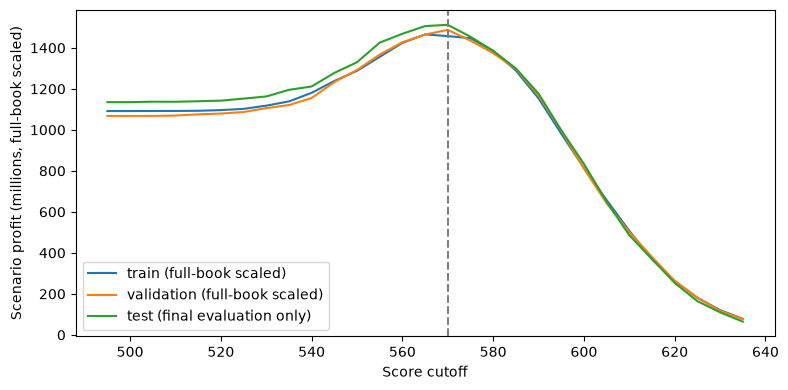

Validation-selected profit-maximising cutoff: 570


,cutoff,approved,approval_rate,defaults,bad_rate,revenue_m,losses_m,profit_m
9,540,16363,0.9864,1438,0.0879,490.0891,308.3512,181.7378
11,550,15873,0.9569,1303,0.0821,476.9503,277.4715,199.4788
13,560,14685,0.8853,1060,0.0722,442.7067,222.4051,220.3016
15,570,13002,0.7838,796,0.0612,392.3123,165.4825,226.8299
17,580,10615,0.6399,550,0.0518,317.8633,110.0407,207.8227
19,590,7974,0.4807,313,0.0393,236.6864,60.2045,176.4820
21,600,5318,0.3206,160,0.0301,154.7502,29.6464,125.1038
23,610,3134,0.1889,87,0.0278,88.9582,16.0637,72.8946
25,620,1613,0.0972,37,0.0229,43.9276,5.9333,37.9943
27,630,703,0.0424,11,0.0156,18.4301,1.9390,16.4911


,cutoff,approved,approval_rate,defaults,bad_rate,revenue_m,losses_m,profit_m
policy,,,,,,,,
approve everyone,495,16588,1.0000,1509,0.0910,496.0477,325.7714,170.2763
cutoff 570,570,13002,0.7838,796,0.0612,392.3123,165.4825,226.8299


In [42]:
# UPDATED — defensible hypothetical term, validation-based cutoff, final test only for reporting.
APR, COST_OF_FUNDS, LGD = 0.15, 0.05, 0.70
ASSUMED_TERM_MONTHS = 24  # POLICY SCENARIO, not observed from this dataset

def total_interest(principal, months, apr):
    p = np.asarray(principal, dtype=float)
    m = np.asarray(months, dtype=float)
    if apr == 0:
        return np.zeros_like(p, dtype=float)
    r = apr / 12
    payment = p * r / (1 - (1 + r) ** (-m))
    return payment * m - p

def profit_frame(data, score, months=ASSUMED_TERM_MONTHS, apr=APR,
                 funding_cost=COST_OF_FUNDS, lgd=LGD):
    info = loan_info.loc[data.index]
    f = pd.DataFrame({'score': score['score'].values,
                      'TARGET': data['TARGET'].values,
                      'loan': info['AMT_CREDIT'].values,
                      'term': float(months)}, index=data.index)
    ni = total_interest(f.loan, f.term, apr) - total_interest(f.loan, f.term, funding_cost)
    f['profit'] = np.where(f.TARGET == 0, ni, -lgd * f.loan)
    return f

def profit_curve(f, cutoffs):
    rows = []
    for cutoff in cutoffs:
        a = f[f.score >= cutoff]
        goods, bads = a[a.TARGET == 0], a[a.TARGET == 1]
        rows.append(dict(cutoff=cutoff, approved=len(a),
                         approval_rate=len(a) / len(f), defaults=len(bads),
                         bad_rate=len(bads) / max(len(a), 1),
                         revenue_m=goods.profit.sum() / 1e6,
                         losses_m=-bads.profit.sum() / 1e6,
                         profit_m=a.profit.sum() / 1e6))
    return pd.DataFrame(rows)

pf_train = profit_frame(train, train_score)
pf_valid = profit_frame(valid, valid_score)
curve_train = profit_curve(pf_train, cutoffs)
curve_valid = profit_curve(pf_valid, cutoffs)
best_cutoff = int(curve_valid.loc[curve_valid.profit_m.idxmax(), 'cutoff'])

# Test is used ONCE after selection for independent reporting.
pf_test = profit_frame(test, test_score)
curve_test = profit_curve(pf_test, cutoffs)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve_train.cutoff, curve_train.profit_m * len(df) / len(train), label='train (full-book scaled)')
ax.plot(curve_valid.cutoff, curve_valid.profit_m * len(df) / len(valid), label='validation (full-book scaled)')
ax.plot(curve_test.cutoff, curve_test.profit_m * len(df) / len(test), label='test (final evaluation only)')
ax.axvline(best_cutoff, ls='--', c='grey')
ax.set_xlabel('Score cutoff'); ax.set_ylabel('Scenario profit (millions, full-book scaled)')
ax.legend(); plt.tight_layout(); plt.savefig('g7_profit_curve.png', dpi=150); plt.show()

print('Validation-selected profit-maximising cutoff:', best_cutoff)
profit_table = curve_test[((curve_test.cutoff % 10 == 0) & (curve_test.cutoff >= 540)) |
                          (curve_test.cutoff == best_cutoff)]
display(profit_table.round(4))
summary_cut = pd.concat([curve_test.iloc[[0]].assign(policy='approve everyone'),
                         curve_test[curve_test.cutoff == best_cutoff].assign(
                             policy=f'cutoff {best_cutoff}')])
display(summary_cut.set_index('policy').round(4))

In [43]:
# NEW — sensitivity of the recommended cutoff to assumed tenor and loss severity.
# Assess on VALIDATION only; test remains untouched for tuning.
sensitivity = []
for tenor in [12, 24, 36]:
    for severity in [0.50, 0.70, 0.90]:
        scenario = profit_frame(valid, valid_score, months=tenor, lgd=severity)
        c = profit_curve(scenario, cutoffs)
        optimum = c.loc[c.profit_m.idxmax()]
        chosen = c.loc[c.cutoff == best_cutoff].iloc[0]
        sensitivity.append({'term_months': tenor, 'LGD': severity,
                            'optimal_cutoff_on_validation': int(optimum.cutoff),
                            'profit_at_original_cutoff_m': chosen.profit_m,
                            'maximum_profit_m': optimum.profit_m})
sensitivity = pd.DataFrame(sensitivity)
display(sensitivity.round(3))
sensitivity.to_csv('g7_profit_sensitivity.csv', index=False)


,term_months,LGD,optimal_cutoff_on_validation,profit_at_original_cutoff_m,maximum_profit_m
0,12,0.5,585,76.859,80.104
1,12,0.7,590,28.545,57.128
2,12,0.9,595,-19.768,39.903
3,24,0.5,560,271.478,279.518
4,24,0.7,570,223.164,223.164
5,24,0.9,570,174.851,174.851
6,36,0.5,550,477.702,524.333
7,36,0.7,555,429.388,448.833
8,36,0.9,565,381.075,383.240


In [44]:
# UPDATED — derive pricing from validation, never actual test outcomes.
def breakeven_apr(g):
    if len(g) == 0:
        return pd.Series({'applicants': 0, 'bad_rate': np.nan, 'breakeven_APR': np.nan})
    def band_profit(apr):
        ni = total_interest(g.loan, g.term, apr) - total_interest(g.loan, g.term, COST_OF_FUNDS)
        return ((1 - g.TARGET) * ni - g.TARGET * LGD * g.loan).sum()
    lo, hi = 0.0, 2.0
    if band_profit(hi) < 0:
        return pd.Series({'applicants': len(g), 'bad_rate': g.TARGET.mean(),
                          'breakeven_APR': np.nan})
    for _ in range(60):
        mid = (lo + hi) / 2
        if band_profit(mid) < 0:
            lo = mid
        else:
            hi = mid
    return pd.Series({'applicants': len(g), 'bad_rate': g.TARGET.mean(),
                      'breakeven_APR': hi})

edges = [-np.inf, best_cutoff, best_cutoff + 20, best_cutoff + 40,
         best_cutoff + 60, np.inf]
pf_valid['band'] = pd.cut(pf_valid.score, edges, right=False)
pricing = pd.DataFrame([
    breakeven_apr(pf_valid.loc[pf_valid.band == band])
    for band in pf_valid['band'].cat.categories
], index=pf_valid['band'].cat.categories)
pricing.index.name = 'band'
print('Pricing estimated from VALIDATION outcomes only; treat as a scenario, not a deployed APR.')
display(pricing.round(4))

Pricing estimated from VALIDATION outcomes only; treat as a scenario, not a deployed APR.


,applicants,bad_rate,breakeven_APR
band,,,
"[-inf, 570.0)",3577.0,0.1996,0.2086
"[570.0, 590.0)",5018.0,0.0967,0.1195
"[590.0, 610.0)",4839.0,0.0490,0.0833
"[610.0, 630.0)",2410.0,0.0253,0.0682
"[630.0, inf)",743.0,0.0148,0.0599


**Risk-based pricing tiers and origination policy.** Each approved band becomes a pricing tier. The indicative rate is
the band's break-even APR plus a margin for operating costs and profit, rounded up to the nearest 0.5%. Lower-scoring
tiers get more checks before the loan is paid out. The margin and the checks are business decisions.

In [45]:
MARGIN = 0.03  # illustrative operating-cost / target-margin assumption

tiers = pricing.reset_index(drop=True)
tiers.insert(0, 'score_band', [f'below {best_cutoff}', f'{best_cutoff}-{best_cutoff + 19}',
                              f'{best_cutoff + 20}-{best_cutoff + 39}',
                              f'{best_cutoff + 40}-{best_cutoff + 59}',
                              f'{best_cutoff + 60} and above'])
tiers.insert(0, 'tier', ['Decline', 'Tier 4 (Higher risk)', 'Tier 3 (Standard)',
                         'Tier 2 (Near prime)', 'Tier 1 (Prime)'])
tiers['indicative_APR'] = np.ceil((tiers['breakeven_APR'] + MARGIN) * 200) / 200
tiers.loc[0, 'indicative_APR'] = np.nan
tiers['origination_policy'] = [
    'Decline, or refer for a co-signer or security',
    'Approve after full income and verified clinic-plan review',
    'Approve after income and clinic-plan checks',
    'Approve with standard documents and verified clinic quote',
    'Approve with standard documents; verify clinic before direct payment',
]
assert len(tiers) == 5
if (tiers.loc[1:4, 'applicants'] < 100).any():
    print('CAUTION: some validation pricing bands are small; rates may be unstable.')
print('Validation-derived APR tiers (not necessarily market-legal prices):')
display(tiers.iloc[::-1].reset_index(drop=True).round(4))
tiers.to_csv('g7_pricing_scenario_validation.csv', index=False)

Validation-derived APR tiers (not necessarily market-legal prices):


,tier,score_band,applicants,bad_rate,breakeven_APR,indicative_APR,origination_policy
0,Tier 1 (Prime),630 and above,743.0,0.0148,0.0599,0.090,Approve with standard documents; verify clinic...
1,Tier 2 (Near prime),610-629,2410.0,0.0253,0.0682,0.100,Approve with standard documents and verified c...
2,Tier 3 (Standard),590-609,4839.0,0.0490,0.0833,0.115,Approve after income and clinic-plan checks
3,Tier 4 (Higher risk),570-589,5018.0,0.0967,0.1195,0.150,Approve after full income and verified clinic-...
4,Decline,below 570,3577.0,0.1996,0.2086,NaN,"Decline, or refer for a co-signer or security"


**PCC measures at the chosen cutoff**

In [46]:
pcc_at(best_cutoff)

*** Train at 570 ***
                               Predicted: Good payer (0) Predicted: Payment difficulty (1)
Actual: Good payer (0)                      56,597  (TP)                      13,773  (FN)
Actual: Payment difficulty (1)               3,767  (FP)                       3,271  (TN)
                        precision    recall  f1-score   support

        Good payer (0)       0.94      0.80      0.87     70370
Payment difficulty (1)       0.19      0.46      0.27      7038

              accuracy                           0.77     77408
             macro avg       0.56      0.63      0.57     77408
          weighted avg       0.87      0.77      0.81     77408

*** Validation at 570 ***
                               Predicted: Good payer (0) Predicted: Payment difficulty (1)
Actual: Good payer (0)                      12,216  (TP)                       2,863  (FN)
Actual: Payment difficulty (1)                 794  (FP)                         714  (TN)
                    

**Summary measures at the chosen cutoff (test set).** As in the Week 11 lab, a good payer is the *positive* class.
* **Accuracy** = share of all applicants classified correctly; **error rate** = 1 − accuracy.
* **Sensitivity (recall)** = share of good payers who are approved.
* **Specificity** = share of defaulters who are declined.
* **Precision** = share of approved applicants who repay.
* **F1 score** = the balance of precision and recall for good payers: 2 × precision × recall / (precision + recall).

In [47]:
pred_good = (test_score['score'].values >= best_cutoff)
actual_good = (y_test.values == 0)
TP = int((pred_good & actual_good).sum());   FN = int((~pred_good & actual_good).sum())
FP = int((pred_good & ~actual_good).sum());  TN = int((~pred_good & ~actual_good).sum())
accuracy = (TP + TN) / len(actual_good)
precision, recall = TP / (TP + FP), TP / (TP + FN)
cutoff_measures = pd.Series({
    'Accuracy': accuracy,
    'Error rate': 1 - accuracy,
    'Sensitivity / recall (good payers approved)': recall,
    'Specificity (defaulters declined)': TN / (TN + FP),
    'Precision (approved applicants who repay)': precision,
    'F1 score (good payers)': 2 * precision * recall / (precision + recall)})
cutoff_measures.map('{:.2%}'.format)

Accuracy                                       77.88%
Error rate                                     22.12%
Sensitivity / recall (good payers approved)    80.95%
Specificity (defaulters declined)              47.25%
Precision (approved applicants who repay)      93.88%
F1 score (good payers)                         86.93%
dtype: object

## Part 8. Scorecard walkthrough (Week 11 Ex Q1 style)
Three test applicants at the 10th, 50th and 90th percentile of score. Their points are looked up bin by bin with
`sc.scorecard_ply(..., only_total_score=False)`, added up, and compared with the cutoff.

In [48]:
# UPDATED — verify each applicant's point total matches the scoring pipeline.
examples = []
for q in (0.10, 0.50, 0.90):
    examples.append((test_score['score'] - test_score['score'].quantile(q)).abs().idxmin())
walkthrough = []
for i in examples:
    appl = test.loc[[i], [c[:-4] for c in selected]]
    pts = sc.scorecard_ply(appl, card, only_total_score=False).transpose()
    total = int(pts.loc['score'].iloc[0])
    assert total == int(test_score.loc[i, 'score']), f'Point total mismatch for index {i}'
    pts = pts.drop(index='score'); pts.index = pts.index.str.replace('_points', '', regex=False)
    summary = pd.concat([appl.transpose(), pts], axis=1)
    summary.columns = ['App Value', 'Points']
    sid = int(df.loc[i, 'SK_ID_CURR'])
    decision = 'APPROVE' if total >= best_cutoff else 'DECLINE'
    print(f'\nApplicant {sid}: total {total} -> {decision} (cutoff {best_cutoff}); actual TARGET={test.loc[i, "TARGET"]}')
    print(summary.to_string())
    walkthrough.append({'SK_ID_CURR': sid, 'score': total, 'decision': decision,
                        'observed_payment_difficulty': int(test.loc[i, 'TARGET'])})
walkthrough = pd.DataFrame(walkthrough)
walkthrough.to_csv('g7_applicant_walkthrough_validation.csv', index=False)
print('WALKTHROUGH AUDIT: all 3 score totals match the final test score output')


Applicant 177312: total 558 -> DECLINE (cutoff 570); actual TARGET=0
                                                 App Value  Points
BUR_DEBT_TO_CREDIT                                 0.38401    43.0
EXT_SOURCE_1                                           NaN    40.0
TERM_MONTHS                                       16.45933    37.0
YEARS_EMPLOYED                                    0.317591    35.0
BUR_N_ACTIVE                                           6.0    29.0
BUR_SHARE_OVERDUE                                      0.0    46.0
YEARS_PHONE_CHANGE                                 4.29295    46.0
REGION_RATING_CLIENT_W_CITY                              3    32.0
NAME_EDUCATION_TYPE          Secondary / secondary special    39.0
AMT_CREDIT                                        387000.0    39.0
BUR_HISTORY_YEARS                                 5.516769    44.0
BUR_N_OPENED_12M                                       1.0    43.0
BUR_UTILISATION                                   0.591302 

In [49]:
# NEW — real-world prediction contract: future rows only need the final selected predictor fields.
final_raw_features = [name[:-4] for name in selected]
print('Features required for scoring a new applicant:', final_raw_features)
minimal_test = test[final_raw_features].copy()
reduced_scores = sc.scorecard_ply(minimal_test, card)
reduced_scores.index = minimal_test.index
assert np.array_equal(reduced_scores['score'].to_numpy(), test_score['score'].to_numpy())
pd.DataFrame({'required_raw_feature': final_raw_features}).to_csv('g7_deployment_features.csv', index=False)
print('DEPLOYMENT AUDIT: removing all other predictor columns does not change the score.')

Features required for scoring a new applicant: ['BUR_DEBT_TO_CREDIT', 'EXT_SOURCE_1', 'TERM_MONTHS', 'YEARS_EMPLOYED', 'BUR_N_ACTIVE', 'BUR_SHARE_OVERDUE', 'YEARS_PHONE_CHANGE', 'REGION_RATING_CLIENT_W_CITY', 'NAME_EDUCATION_TYPE', 'AMT_CREDIT', 'BUR_HISTORY_YEARS', 'BUR_N_OPENED_12M', 'BUR_UTILISATION', 'REG_CITY_NOT_WORK_CITY']
DEPLOYMENT AUDIT: removing all other predictor columns does not change the score.


## Summary

In [50]:
acc = curve_test.loc[curve_test.cutoff == best_cutoff].iloc[0]
allp = curve_test.iloc[0]
print('=' * 78)
print('SCORECARD SUMMARY — G1-7 Medical Procedure Loan (reviewed pipeline)')
print('=' * 78)
print(f'segment {len(df):,} | train {len(train):,} | valid {len(valid):,} | test {len(test):,}')
print(f'observed segment payment-difficulty rate: {df.TARGET.mean():.2%}')
print(f'screening: {len(iv_fine)} candidates -> {len(screened)} fine IV >= .02 -> '
      f'{len(coarse_kept)} coarse IV >= .02 -> {len(candidates)} WOE candidates -> '
      f'{len(selected)} model predictors')
print(f'final test: AUC {perf.loc["test", "AUC"]:.4f} | Gini {perf.loc["test", "Gini"]:.4f} | '
      f'KS {perf.loc["test", "KS"]:.4f}')
print('score scale: 600 points = 1:19 bad:good odds; PDO 20')
print(f'cutoff {best_cutoff} (VALIDATION-CHOSEN): test approval {acc.approval_rate:.1%} | '
      f'approved bad rate {acc.bad_rate:.2%} vs {allp.bad_rate:.2%} if all approved')
print(f'test scenario profit {acc.profit_m:.1f}m vs {allp.profit_m:.1f}m (illustrative only)')
print(f'Assumed term {ASSUMED_TERM_MONTHS} months; APR {APR:.0%}; COF {COST_OF_FUNDS:.0%}; LGD {LGD:.0%}')
assert np.isfinite(perf.loc['test', 'AUC'])
assert acc.approved == int((test_score.score >= best_cutoff).sum())
print('FINAL AUDIT: scorecard + cutoff + test accounting consistent')

SCORECARD SUMMARY — G1-7 Medical Procedure Loan (reviewed pipeline)
segment 110,583 | train 77,408 | valid 16,587 | test 16,588
observed segment payment-difficulty rate: 9.09%
screening: 104 candidates -> 43 fine IV >= .02 -> 36 coarse IV >= .02 -> 33 WOE candidates -> 14 model predictors
final test: AUC 0.7139 | Gini 0.4278 | KS 0.3091
score scale: 600 points = 1:19 bad:good odds; PDO 20
cutoff 570 (VALIDATION-CHOSEN): test approval 78.4% | approved bad rate 6.12% vs 9.10% if all approved
test scenario profit 226.8m vs 170.3m (illustrative only)
Assumed term 24 months; APR 15%; COF 5%; LGD 70%
FINAL AUDIT: scorecard + cutoff + test accounting consistent
